# Chargement et exploration du jeu de données

Ce notebook a pour objectif de charger correctement le fichier CSV contenant les variables explicatives `X1` à `X16` et la variable cible `y`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
import numpy as np
chemin_fichier = 'BEED_Data.csv'


In [2]:
df = pd.read_csv(chemin_fichier)

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,y
0,4,7,18,25,28,27,20,10,-10,-18,-20,-16,13,32,12,10,0
1,87,114,120,106,76,54,28,5,-19,-49,-85,-102,-100,-89,-61,-21,0
2,-131,-133,-140,-131,-123,-108,-58,-51,-70,-77,-76,-76,-73,-57,-40,-14,0
3,68,104,73,34,-12,-26,-38,-36,-67,-88,-25,31,18,-4,6,-29,0
4,-67,-90,-97,-94,-86,-71,-43,-11,23,46,58,50,39,19,-9,-41,0


## Vérification de la structure et de la qualité des données

In [3]:
df.info()
print(len(df))

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      8000 non-null   int64
 1   X2      8000 non-null   int64
 2   X3      8000 non-null   int64
 3   X4      8000 non-null   int64
 4   X5      8000 non-null   int64
 5   X6      8000 non-null   int64
 6   X7      8000 non-null   int64
 7   X8      8000 non-null   int64
 8   X9      8000 non-null   int64
 9   X10     8000 non-null   int64
 10  X11     8000 non-null   int64
 11  X12     8000 non-null   int64
 12  X13     8000 non-null   int64
 13  X14     8000 non-null   int64
 14  X15     8000 non-null   int64
 15  X16     8000 non-null   int64
 16  y       8000 non-null   int64
dtypes: int64(17)
memory usage: 1.0 MB
8000


In [4]:
print("Répartition de la variable cible 'y' : ")
display(df['y'].value_counts())

Répartition de la variable cible 'y' : 


y
0    2000
1    2000
2    2000
3    2000
Name: count, dtype: int64

In [5]:
def plot_signals(df, n, start=0):
    X_cols = [f"X{i}" for i in range(1, 17)]

    n = min(n, len(df))

    fig, axes = plt.subplots(
        n, 1,
        figsize=(10, 2 * n),
        sharex=True
    )

    # Cas n = 1
    if n == 1:
        axes = [axes]

    for i in range(n):
        signal = df.loc[i+ start, X_cols]
        label = df.loc[i+ start, "y"]

        color = "blue" if label == 0 else "red"

        axes[i].plot(
            range(1, 17),
            signal,
            color=color
        )

        axes[i].set_ylabel(f"y={label}")
        axes[i].grid(True, alpha=0.3)

    axes[-1].set_xlabel("X")
    plt.tight_layout()
    plt.show()

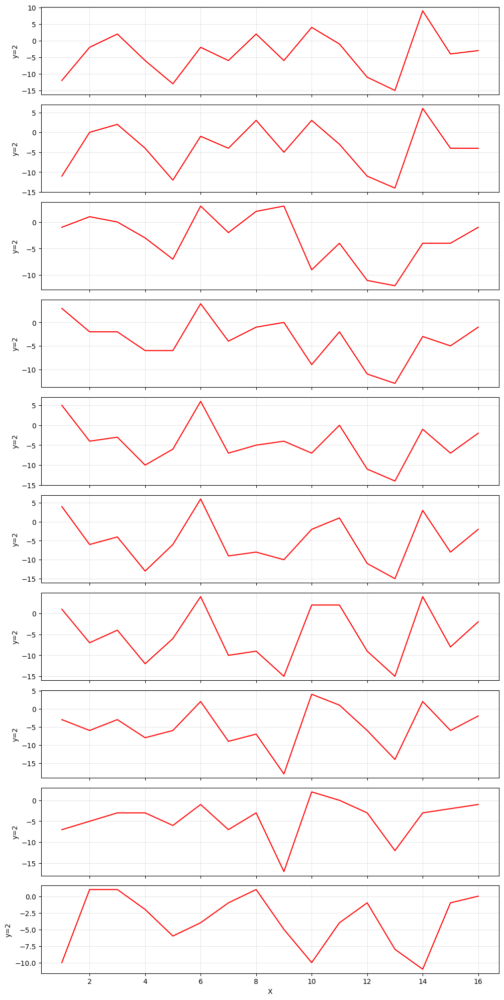

In [6]:
plot_signals(df,10, 5000)

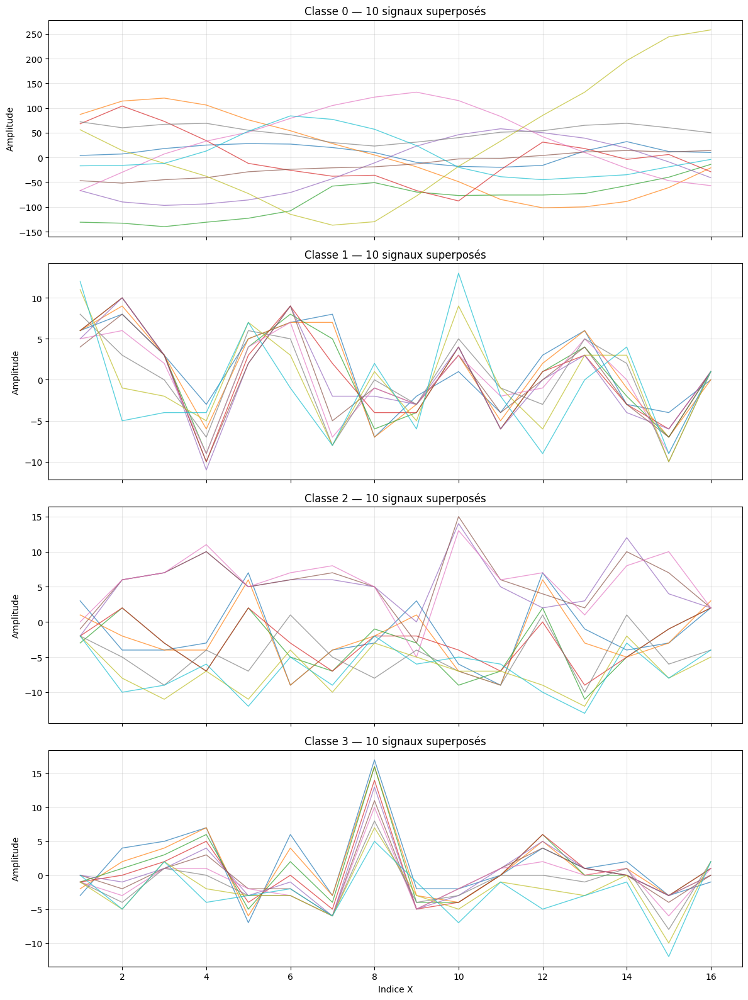

In [7]:
import matplotlib.pyplot as plt

def plot_superposition_10_par_classe(df):
    X_cols = [f"X{i}" for i in range(1, 17)]

    classes = sorted(df["y"].unique())
    fig, axes = plt.subplots(
        len(classes), 1,
        figsize=(12, 4 * len(classes)),
        sharex=True
    )

    if len(classes) == 1:
        axes = [axes]

    for ax, classe in zip(axes, classes):
        # Sélection des 10 premiers signaux de cette classe
        df_classe = df[df["y"] == classe].head(10)

        for _, ligne in df_classe.iterrows():
            signal = ligne[X_cols].to_numpy(dtype=float)
            ax.plot(range(1, 17), signal, alpha=0.7, linewidth=1)

        ax.set_title(f"Classe {classe} — {len(df_classe)} signaux superposés")
        ax.set_ylabel("Amplitude")
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Indice X")
    plt.tight_layout()
    plt.show()


plot_superposition_10_par_classe(df)

In [10]:
def plot_periodograms(df, n, start=0):
    X_cols = [f"X{i}" for i in range(1, 17)]

    n = min(n, len(df) - start)

    fig, ax = plt.subplots(figsize=(10, 6))

    # Dégradés bleu et rouge
    blue_colors = plt.cm.Blues(np.linspace(0.4, 1, n))
    red_colors = plt.cm.Reds(np.linspace(0.4, 1, n))

    blue_i = 0
    red_i = 0

    for i in range(n):

        row = df.iloc[i + start]

        signal = row[X_cols].astype(float).values
        label = row["y"]

        # Calcul du périodogramme
        frequencies, power = periodogram(signal)

        if label == 0:
            color = blue_colors[blue_i]
            blue_i += 1
        else:
            color = red_colors[red_i]
            red_i += 1

        ax.plot(
            frequencies,
            power,
            color=color,
            linewidth=1.5,
            alpha=0.8
        )

    ax.set_xlabel("Fréquence")
    ax.set_ylabel("Puissance")
    ax.set_title(f"Périodogrammes — lignes {start} à {start+n-1}")

    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

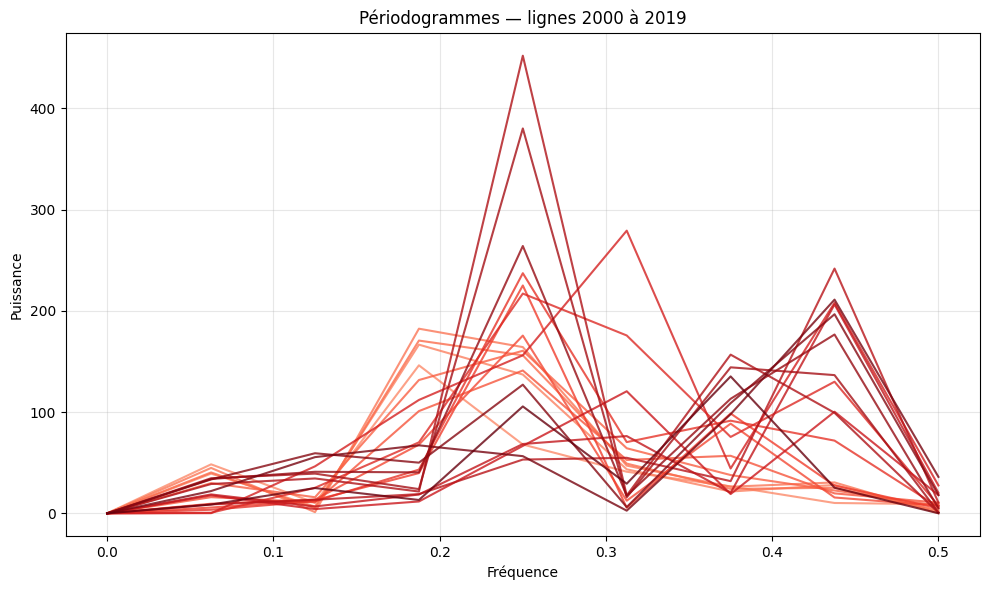

In [11]:
plot_periodograms(df, n=20, start=2000)

In [12]:
segments = [(10, 40), (500, 560), (2100, 2130), (5200,5260), (6000,7500)]
def extract_and_shuffle(df, segments, random_state=None):
    indices = []

    for start, end in segments:
        indices.extend(range(start, end+1))

    subset = df.iloc[indices].copy()

    # Mélange les lignes
    subset = subset.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)

    return subset

In [13]:
new_df = extract_and_shuffle(df, segments)

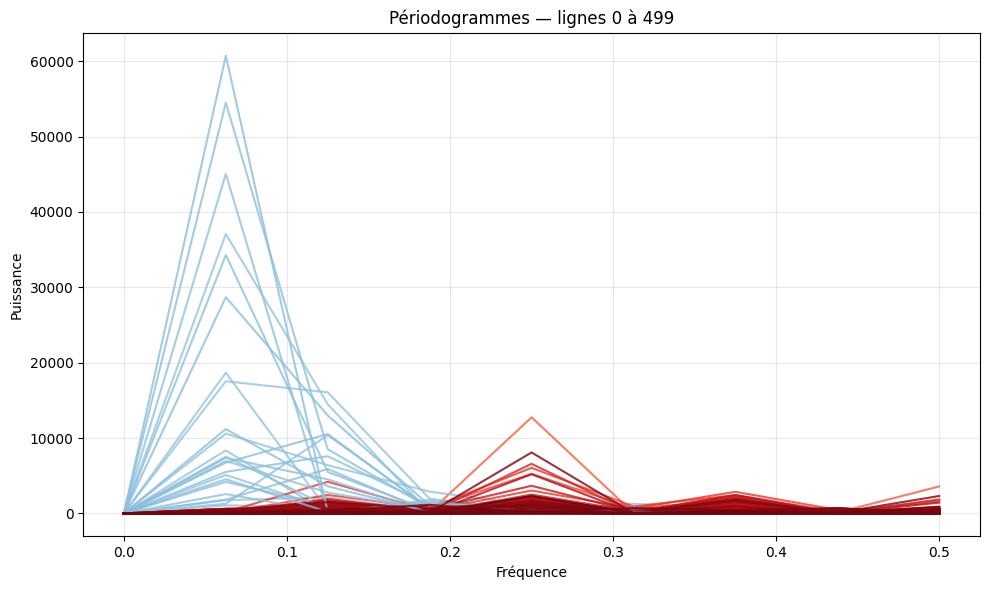

In [14]:
plot_periodograms(new_df, n=500, start=0)

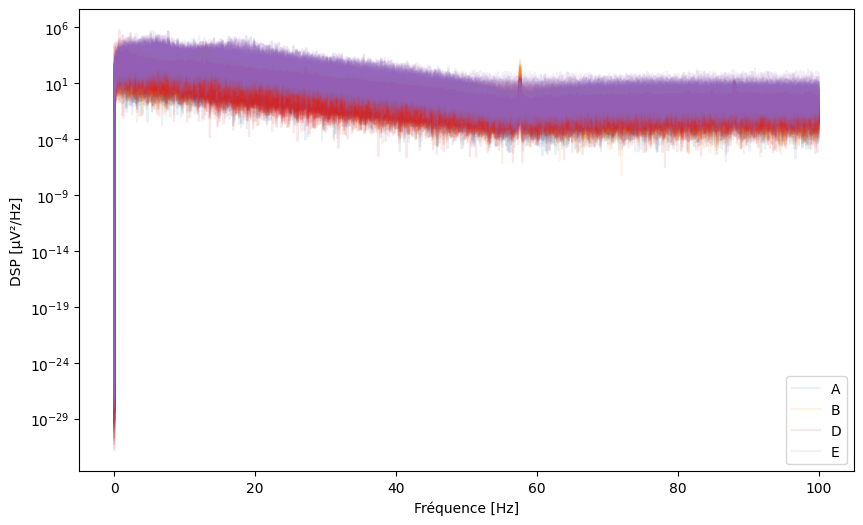

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import periodogram

dossier = Path(r"Epilepsy-EEG")
fs = 200
n_fichiers = 100  # nombre de fichiers par classe

cmap = plt.get_cmap("tab10")
plt.figure(figsize=(10, 6))

classes = [c for c in sorted(dossier.iterdir())
           if c.is_dir() and c.name != "Projetsignal"]

for i, classe in enumerate(classes):
    fichiers = sorted(classe.glob("*.txt"))[:n_fichiers]   # limite ici

    for j, fichier in enumerate(fichiers):
        signal_brut = np.loadtxt(fichier)
        f, Pxx = periodogram(signal_brut, fs=fs)

        plt.semilogy(f, Pxx, alpha=0.1, color=cmap(i),
                     label=classe.name if j == 0 else None)  # 1 label par classe

plt.xlabel("Fréquence [Hz]")
plt.ylabel("DSP [µV²/Hz]")
plt.legend()
plt.show()


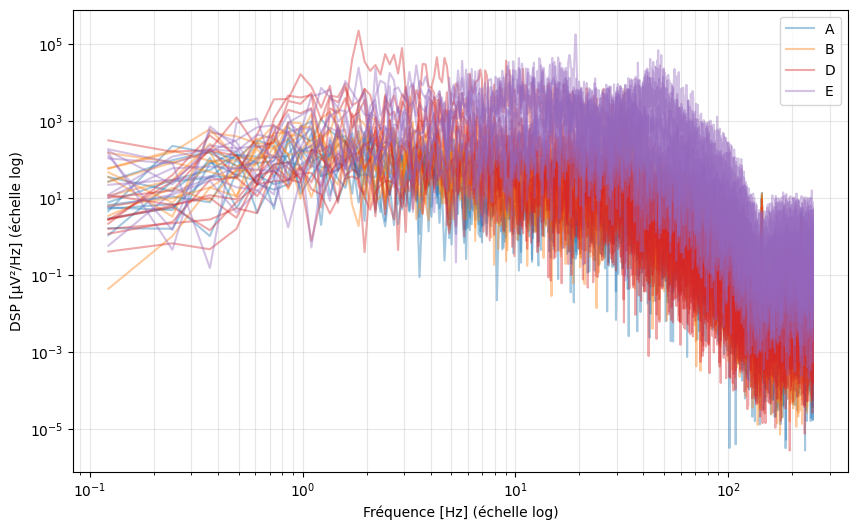

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import periodogram

dossier = Path(r"Epilepsy-EEG")
fs = 500.61      # Hz (dataset Bonn, à vérifier)
n_fichiers = 10  # nombre de fichiers par classe

cmap = plt.get_cmap("tab10")
plt.figure(figsize=(10, 6))

classes = [c for c in sorted(dossier.iterdir())
           if c.is_dir() and c.name != "Projetsignal"]

for i, classe in enumerate(classes):
    fichiers = sorted(classe.glob("*.txt"))[:n_fichiers]

    for j, fichier in enumerate(fichiers):
        signal_brut = np.loadtxt(fichier)
        f, Pxx = periodogram(signal_brut, fs=fs, detrend="constant")

        # on retire f = 0 pour l'axe X logarithmique
        plt.loglog(f[1:], Pxx[1:], alpha=0.4, color=cmap(i),
                   label=classe.name if j == 0 else None)

plt.xlabel("Fréquence [Hz] (échelle log)")
plt.ylabel("DSP [µV²/Hz] (échelle log)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [17]:
import numpy as np
from pathlib import Path

dossier = Path(r"Epilepsy-EEG")
n_attendu = 4097      # points par fichier (dataset Bonn)
nb_fichiers_attendu = 100   # par classe dans Bonn

for classe in sorted(dossier.iterdir()):
    if classe.is_dir() and classe.name != "Projetsignal":
        fichiers = sorted(classe.glob("*.txt"))
        print(f"{classe.name}: {len(fichiers)} fichiers (attendu {nb_fichiers_attendu})")

        for fichier in fichiers:
#            if np.all(x == x[0]):
 #               print(f"{fichier.name}: signal constant")
        
        # plus longue séquence de valeurs identiques consécutives
  #          changements = np.flatnonzero(np.diff(x) != 0)
   #         runs = np.diff(np.concatenate(([-1], changements, [len(x) - 1])))
    #        if runs.max() > 5:
     #           print(f"{fichier.name}: {runs.max()} valeurs identiques consécutives")
      
            try:
                x = np.loadtxt(fichier)
            except Exception as e:
                print(f"  ERREUR lecture {fichier.name}: {e}")
                continue

            if x.ndim != 1 or len(x) != n_attendu:
                print(f"  {fichier.name}: forme {x.shape} (attendu {n_attendu})")
            if np.isnan(x).any() or np.isinf(x).any():
                print(f"  {fichier.name}: {np.isnan(x).sum()} NaN, {np.isinf(x).sum()} inf")

A: 100 fichiers (attendu 100)
B: 100 fichiers (attendu 100)
C: 0 fichiers (attendu 100)
D: 100 fichiers (attendu 100)
E: 100 fichiers (attendu 100)


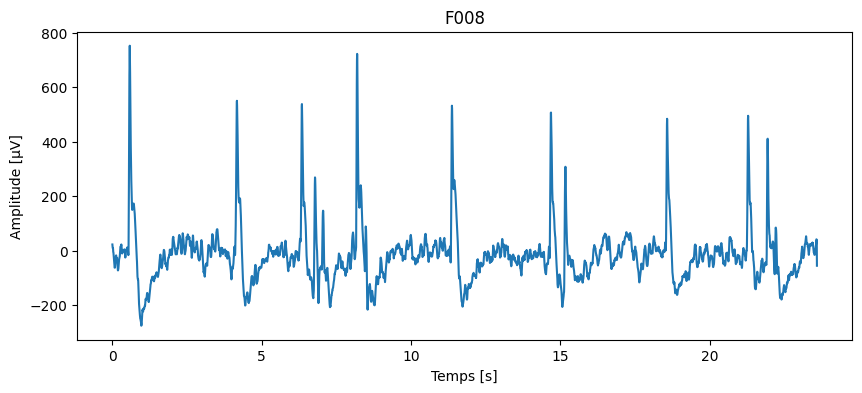

In [18]:


chemin = Path(r"Epilepsy-EEG/D/F008.txt")
fs = 173.61  # Hz (dataset Bonn, à vérifier)

signal_brut = np.loadtxt(chemin)
t = np.arange(len(signal_brut)) / fs   # axe du temps en secondes

plt.figure(figsize=(10, 4))
plt.plot(t, signal_brut)
plt.xlabel("Temps [s]")
plt.ylabel("Amplitude [µV]")
plt.title(chemin.stem)
plt.show()

In [19]:
import numpy as np
import pandas as pd
from pathlib import Path

dossier = Path(r"Epilepsy-EEG")
V_MIN, V_MAX = -2047, 2047

resultats = []

for classe in sorted(dossier.iterdir()):
    if classe.is_dir() and classe.name != "Projetsignal":
        for fichier in sorted(classe.glob("*.txt")):
            x = np.loadtxt(fichier)
            n_min = int(np.sum(x <= V_MIN))
            n_max = int(np.sum(x >= V_MAX))

            if n_min > 0 or n_max > 0:
                resultats.append({
                    "classe": classe.name,
                    "fichier": fichier.name,
                    "n_points": len(x),
                    "n_sat_0": n_min,
                    "n_sat_2047": n_max,
                    "% saturé": 100 * (n_min + n_max) / len(x),
                })

df = pd.DataFrame(resultats)
print(df.sort_values("% saturé", ascending=False).to_string(index=False))
print(f"\n{len(df)} fichier(s) saturé(s)")

classe  fichier  n_points  n_sat_0  n_sat_2047  % saturé
     D F009.txt      4097        0          52  1.269221
     E S065.txt      4097        0          18  0.439346
     E S059.txt      4097        0           2  0.048816

3 fichier(s) saturé(s)


A: 10 fichiers (attendu 100)


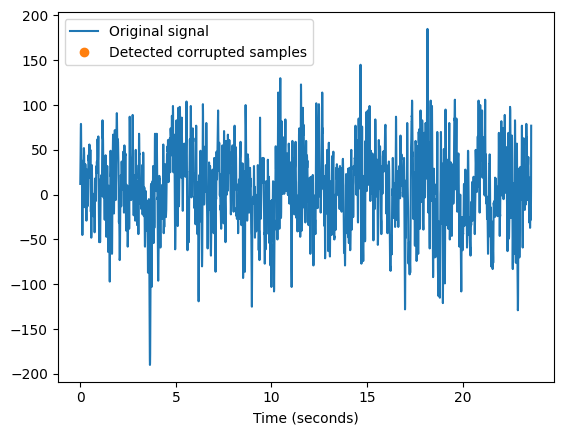

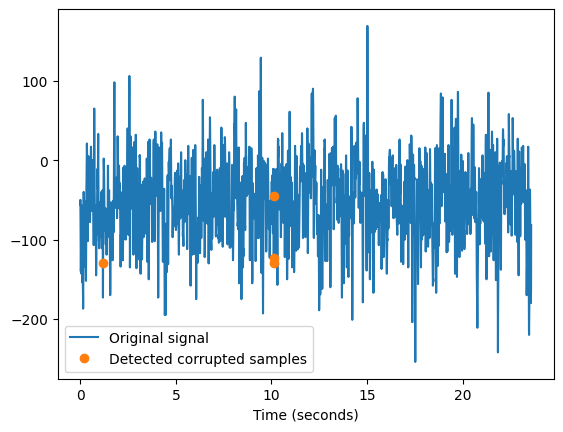

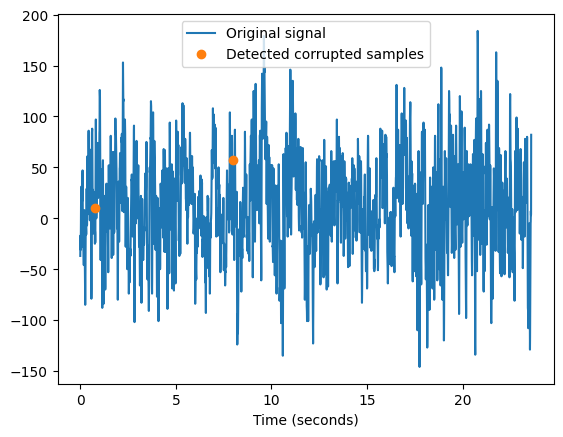

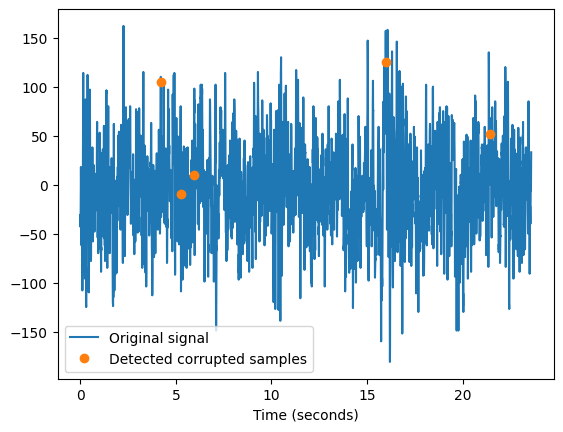

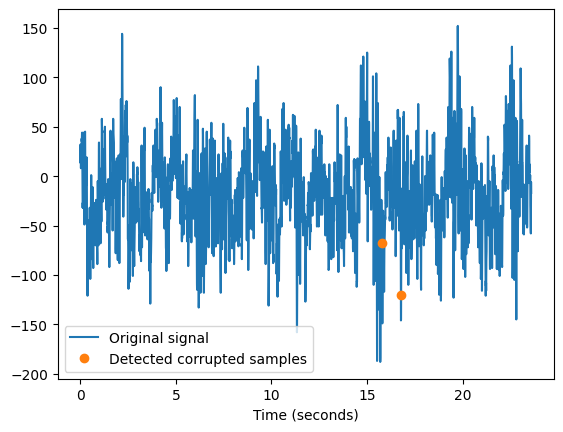

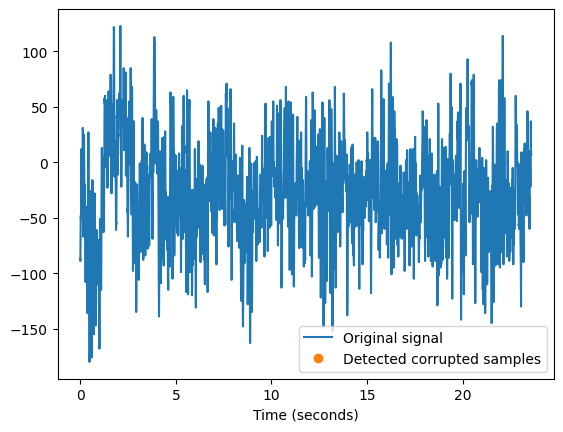

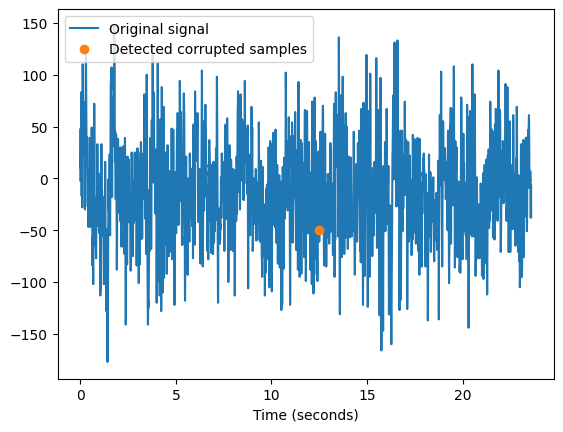

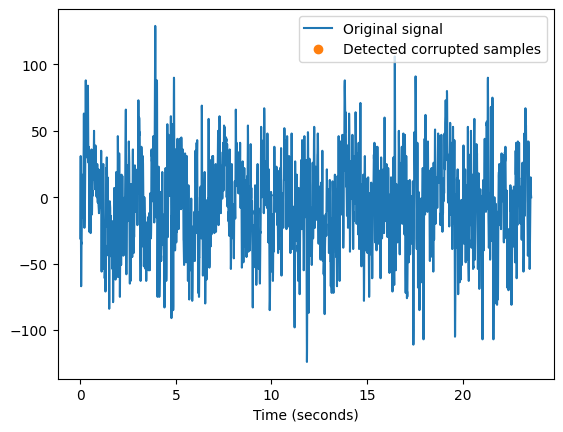

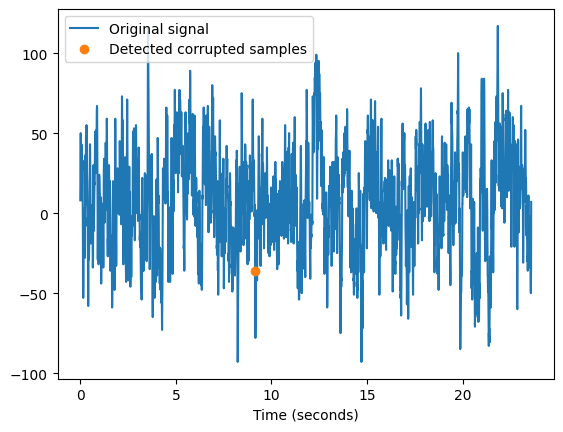

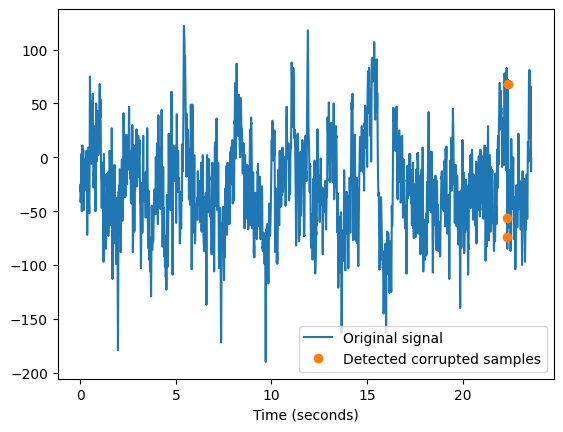

B: 10 fichiers (attendu 100)


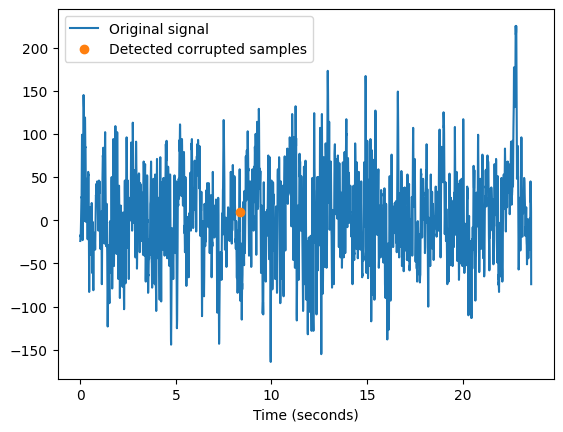

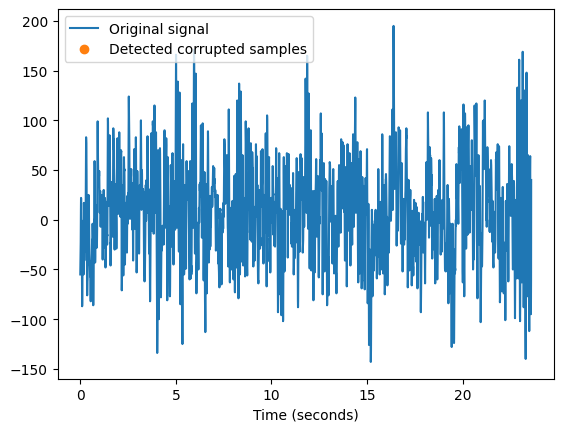

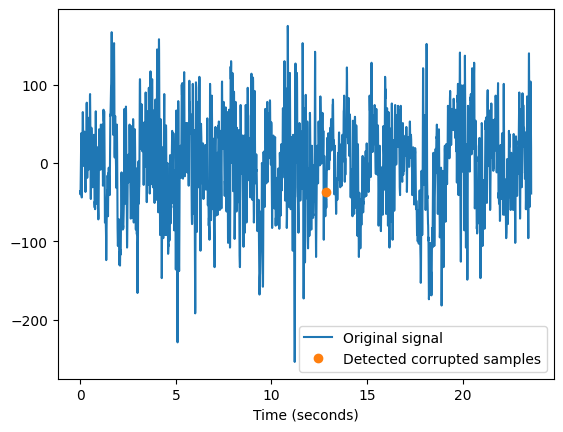

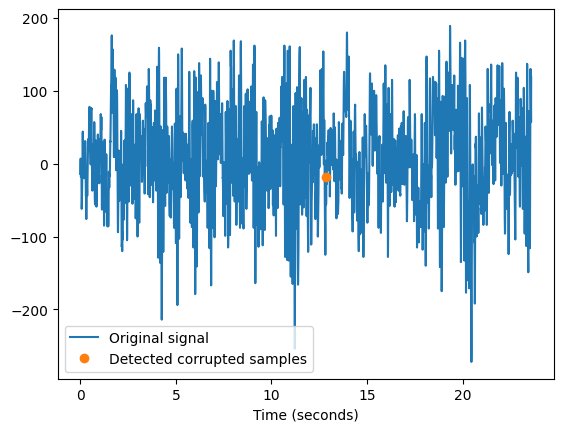

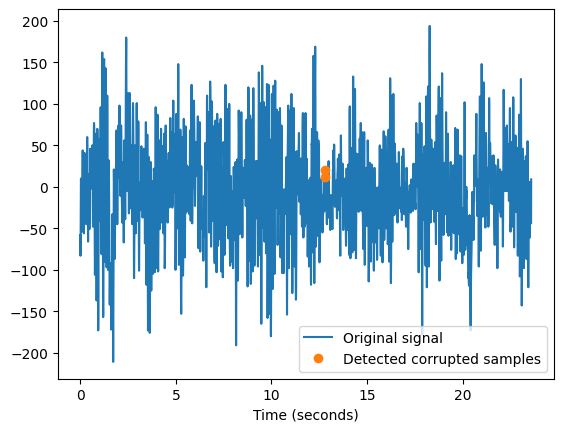

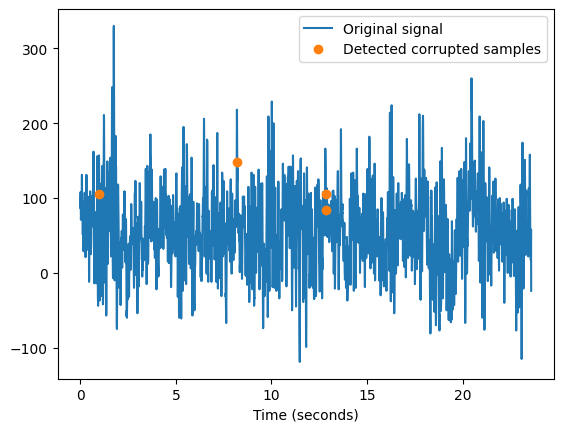

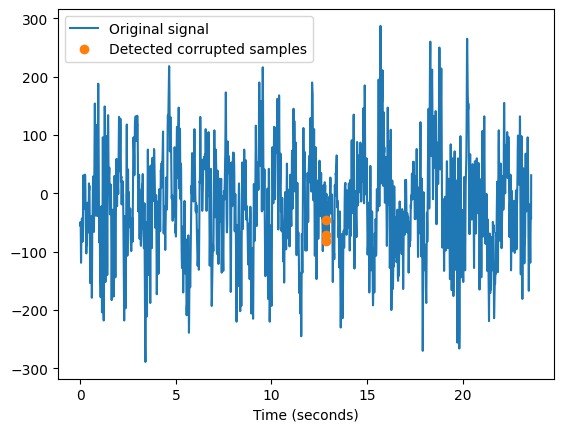

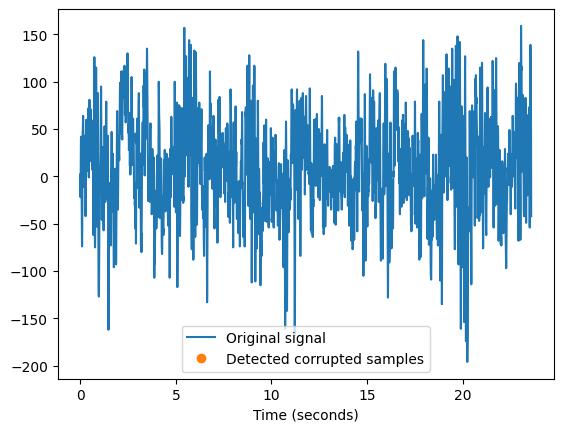

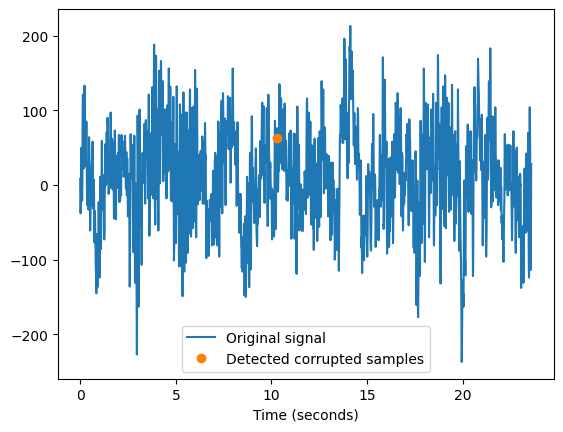

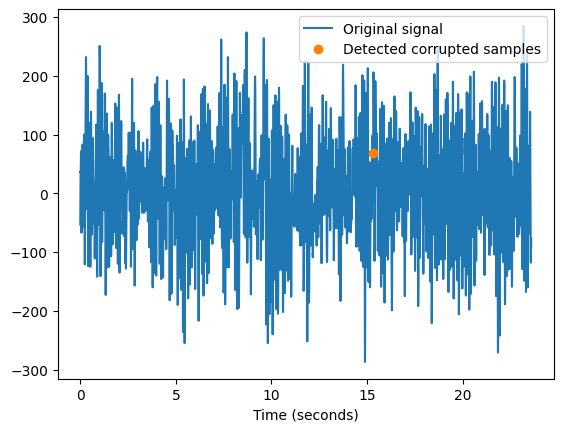

C: 0 fichiers (attendu 100)
D: 10 fichiers (attendu 100)


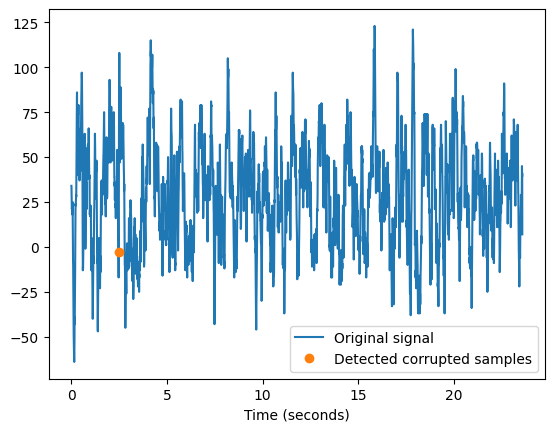

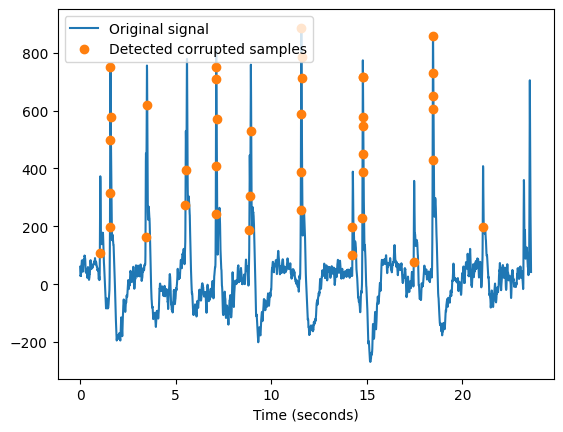

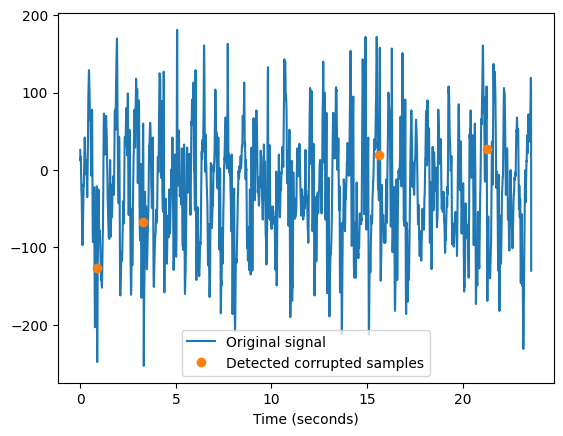

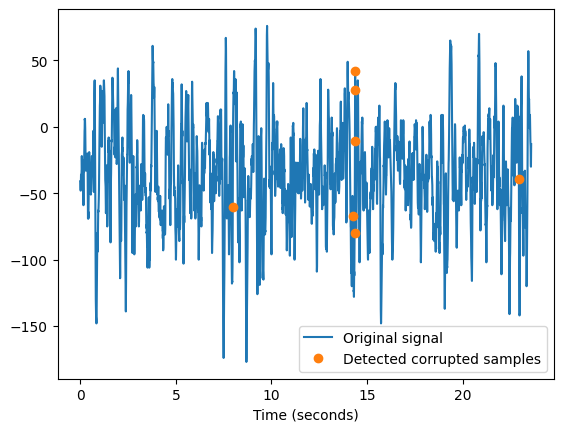

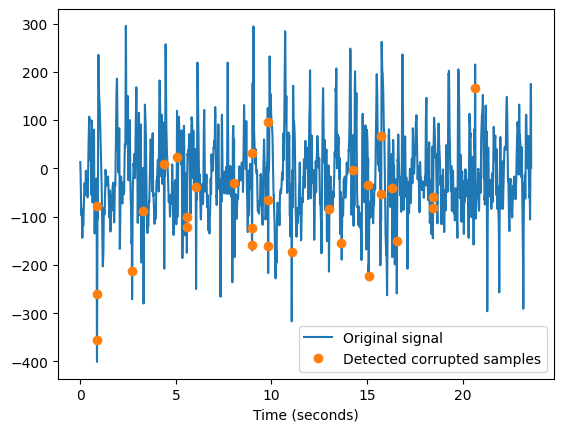

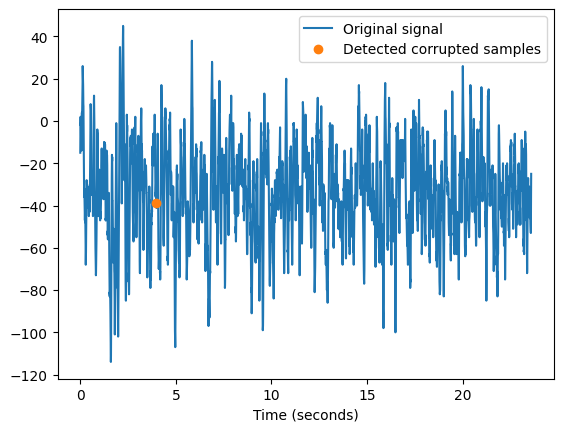

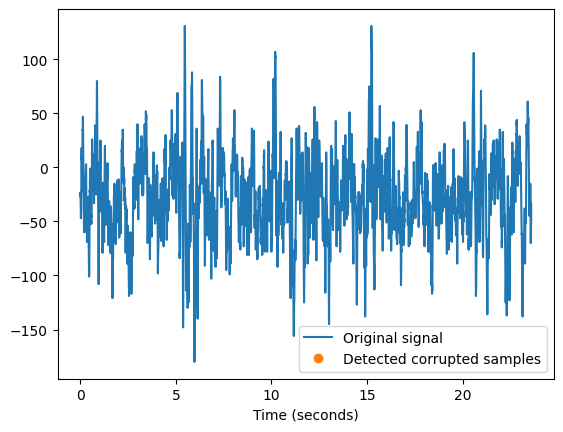

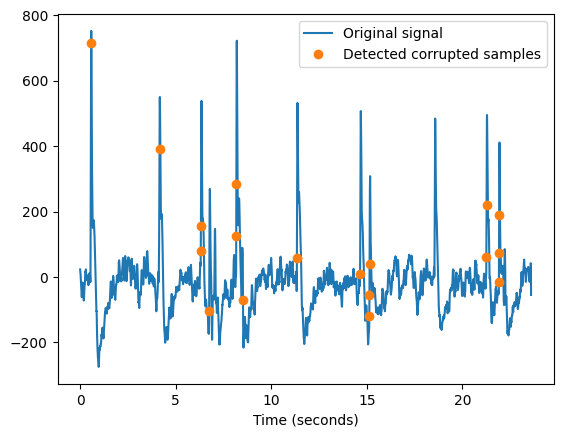

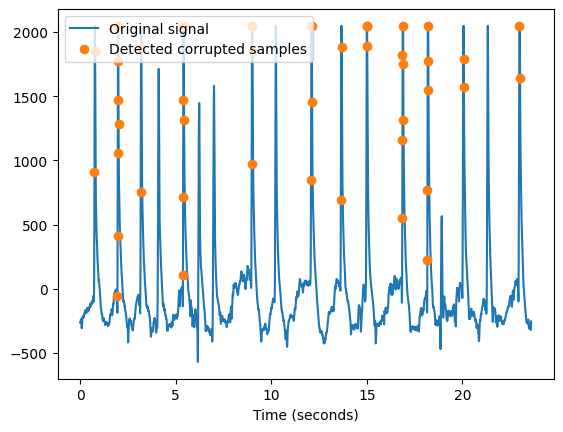

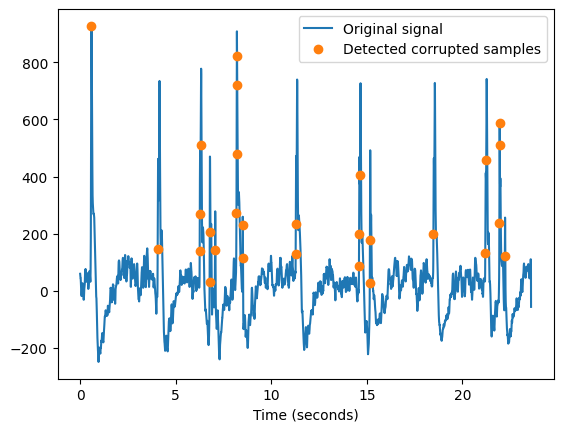

E: 10 fichiers (attendu 100)


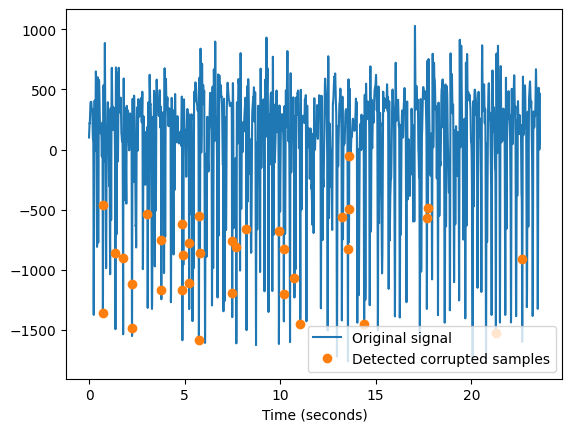

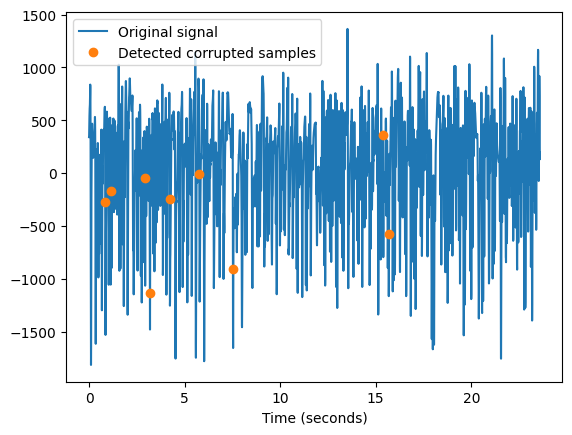

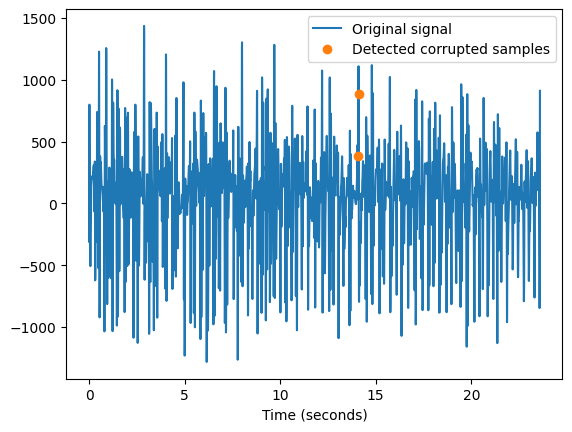

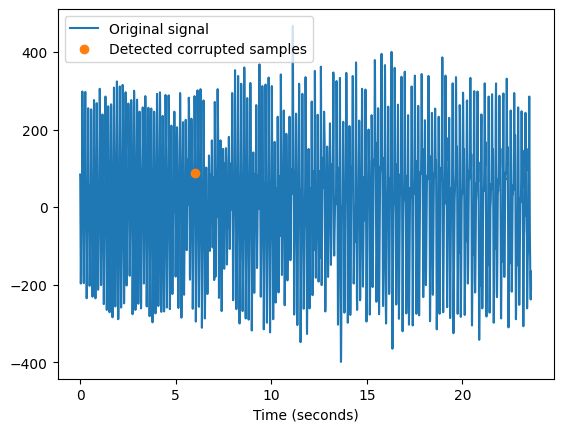

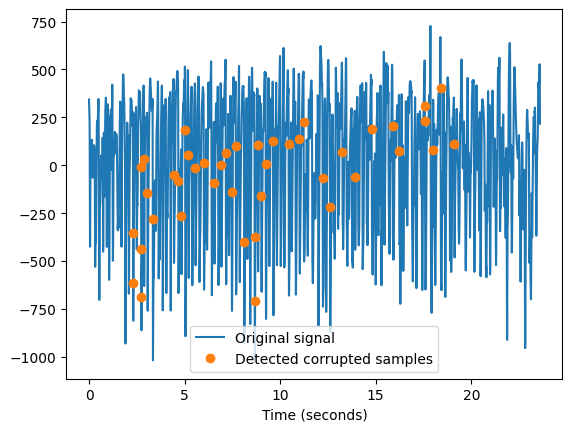

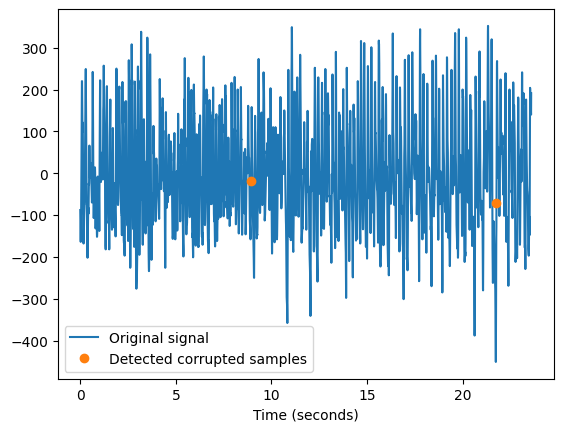

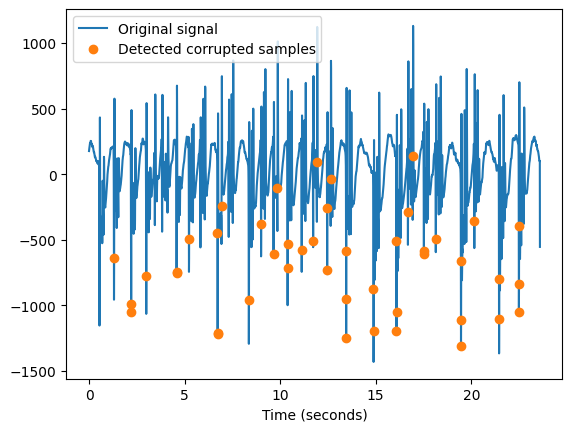

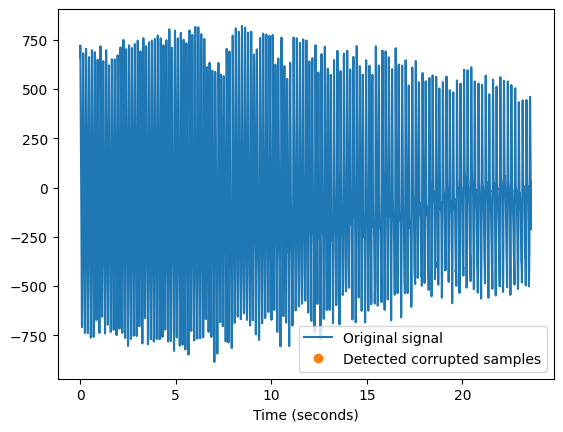

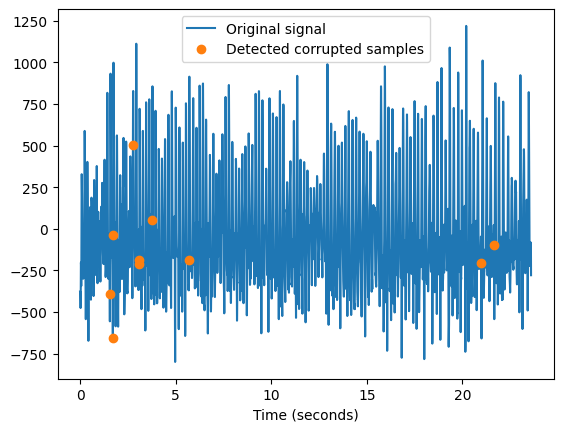

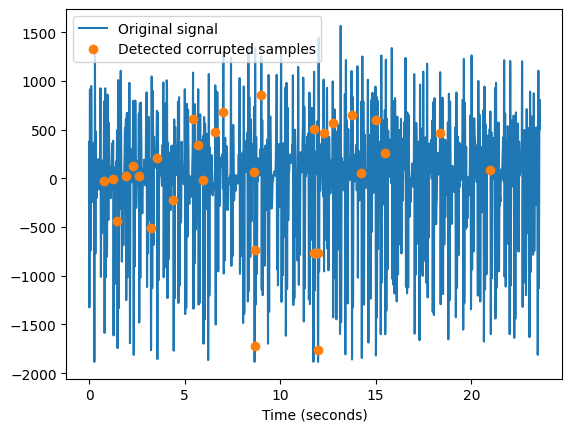

In [20]:
# Detection of corrupted samples based on AR model
from statsmodels.regression.linear_model import yule_walker

def detection_impulsive(x,p,K):
    # Estimation of the AR parameters
    a, sigma_e = yule_walker(x, p, method='mle',demean=True) 
    Nw=np.size(x)
    # Computation of the prediction error
    d=np.zeros((Nw,))
    for j in range(p,Nw):
        d[j]=x[j]-np.sum(np.dot(x[j-p:j],np.flip(a)))
    d=np.abs(d)
    # Thresholding the prediction error to find the locations of the corrupted samples
    lambda_K=K*sigma_e
    T=np.where(d>lambda_K)
    T=T[0]
    T=T[(T>p-1) & (T<Nw-p)]
    return T

dossier = Path(r"Epilepsy-EEG")
n_attendu = 4097      # points par fichier (dataset Bonn)
nb_fichiers_attendu = 100   # par classe dans Bonn

for classe in sorted(dossier.iterdir()):
    if classe.is_dir() and classe.name != "Projetsignal":
        fichiers = sorted(classe.glob("*.txt"))[:10]
        print(f"{classe.name}: {len(fichiers)} fichiers (attendu {nb_fichiers_attendu})")

        for fichier in fichiers:
            try:
                x = np.loadtxt(fichier)
            except Exception as e:
                print(f"  ERREUR lecture {fichier.name}: {e}")
                continue

            T=detection_impulsive(x,100,4)
            plt.figure("Detection of the corrupted samples")
            plt.plot(t,x)
            plt.plot(t[T],x[T],'o')
            plt.xlabel('Time (seconds)')
            plt.legend(('Original signal', 'Detected corrupted samples'))
            plt.show()

In [21]:

import numpy as np
from pathlib import Path

dossier = Path(r"Epilepsy-EEG")

data = {}

for lettre in ["A", "B", "C", "D", "E"]:
    fichiers = sorted(
        f for f in (dossier / lettre).iterdir()
        if f.is_file() and f.suffix.lower() == ".txt"
    )

    data[lettre] = np.array([np.loadtxt(f) for f in fichiers])

# Vérification
for lettre, tab in data.items():
    print(lettre, tab.shape)  # attendu : (100, 4097)


A (100, 4097)
B (100, 4097)
C (100, 4097)
D (100, 4097)
E (100, 4097)


In [22]:
for lettre, tab in data.items():
    print(lettre, type(tab), np.asarray(tab).shape)

A <class 'numpy.ndarray'> (100, 4097)
B <class 'numpy.ndarray'> (100, 4097)
C <class 'numpy.ndarray'> (100, 4097)
D <class 'numpy.ndarray'> (100, 4097)
E <class 'numpy.ndarray'> (100, 4097)


In [23]:
import numpy as np
from scipy.signal import iirnotch, filtfilt, periodogram

fs = 173.61

def mesurer_pic(data, fs, bande=(45, 60)):
    """Fréquence médiane du pic dans la bande, sur tous les fichiers."""
    pics = []
    for tab in data.values():
        f, Pxx = periodogram(tab, fs=fs, detrend="constant", axis=-1)
        m = (f > bande[0]) & (f < bande[1])
        pics.extend(f[m][np.argmax(Pxx[:, m], axis=1)])
    return float(np.median(pics))

def notch_data(data, fs, f0=50.0, Q=30):
    """Applique un filtre notch à f0 sur chaque signal de chaque classe."""
    b, a = iirnotch(w0=f0, Q=Q, fs=fs)
    return {lettre: filtfilt(b, a, tab, axis=-1) for lettre, tab in data.items()}


def notch_data_controle(data, fs, f0=50.0, Q=100, force=0.5):
    """
    Apply a notch filter to each signal, with adjustable strength.

    Parameters
    ----------
    data : dict
        Dictionary of 2D arrays, one per class.
    fs : float
        Sampling frequency in Hz.
    f0 : float
        Notch center frequency in Hz.
    Q : float
        Quality factor. Higher values produce a narrower notch.
    force : float
        Filtering strength between 0 and 1.
        0 = no filtering, 1 = full notch filtering.

    Returns
    -------
    dict
        Filtered signals, preserving the original dictionary structure.
    """
    if not 0 <= force <= 1:
        raise ValueError("force must be between 0 and 1.")

    b, a = iirnotch(w0=f0, Q=Q, fs=fs)

    data_filtre = {}

    for lettre, tab in data.items():
        filtre_complet = filtfilt(b, a, tab, axis=-1)

        # Blend the original and filtered signals
        data_filtre[lettre] = (
            (1 - force) * tab + force * filtre_complet
        )

    return data_filtre


f_pic = mesurer_pic(data, fs)
print(f"Pic médian : {f_pic:.2f} Hz")

data_filtre = notch_data_controle(data, fs, f0=f_pic, Q=100, force = 0.85)

for lettre in data:
    print(lettre, data_filtre[lettre].shape)

Pic médian : 50.00 Hz
A (100, 4097)
B (100, 4097)
C (100, 4097)
D (100, 4097)
E (100, 4097)


In [24]:

def plot_periodograms(data, fs, bande=None, echelle="lin"):
    """
    Plot the mean periodogram for each group of signals.

    Parameters
    ----------
    data : dict
        Dictionary mapping group labels to arrays of shape
        (n_signals, n_samples).
    fs : float
        Sampling frequency in Hz.
    bande : tuple of float, optional
        Frequency range (f_min, f_max) to display, in Hz.
    echelle : str
        Plot scale:
        - "lin"    : linear x and y axes
        - "semilog": logarithmic x-axis, linear y-axis
        - "loglog" : logarithmic x and y axes
    """
    if echelle not in ("lin", "semilog", "loglog"):
        raise ValueError(
            "echelle must be 'lin', 'semilog' or 'loglog'."
        )

    fig, ax = plt.subplots(figsize=(12, 6))

    for lettre, tab in data.items():
        f, Pxx = periodogram(
            tab,
            fs=fs,
            detrend="constant",
            axis=-1
        )

        # Mean power spectral density across signals
        Pxx_moyen = np.mean(Pxx, axis=0)

        # Restrict frequency range if requested
        masque = np.ones_like(f, dtype=bool)
        if bande is not None:
            masque = (f >= bande[0]) & (f <= bande[1])

        # Logarithmic x-axes cannot display zero frequency
        if echelle in ("semilog", "loglog"):
            masque &= f > 0

        # Logarithmic y-axes require strictly positive values
        if echelle == "loglog":
            masque &= Pxx_moyen > 0

        if echelle == "semilog":
            ax.semilogx(
                f[masque], Pxx_moyen[masque], label=lettre
            )
        elif echelle == "loglog":
            ax.loglog(
                f[masque], Pxx_moyen[masque], label=lettre
            )
        else:
            ax.plot(
                f[masque], Pxx_moyen[masque], label=lettre
            )

    ax.set_xlabel("Fréquence (Hz)")
    ax.set_ylabel("Densité spectrale de puissance")
    ax.set_title("Periodogrammes moyens par groupe")
    ax.legend(title="Groupe")
    ax.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    plt.show()


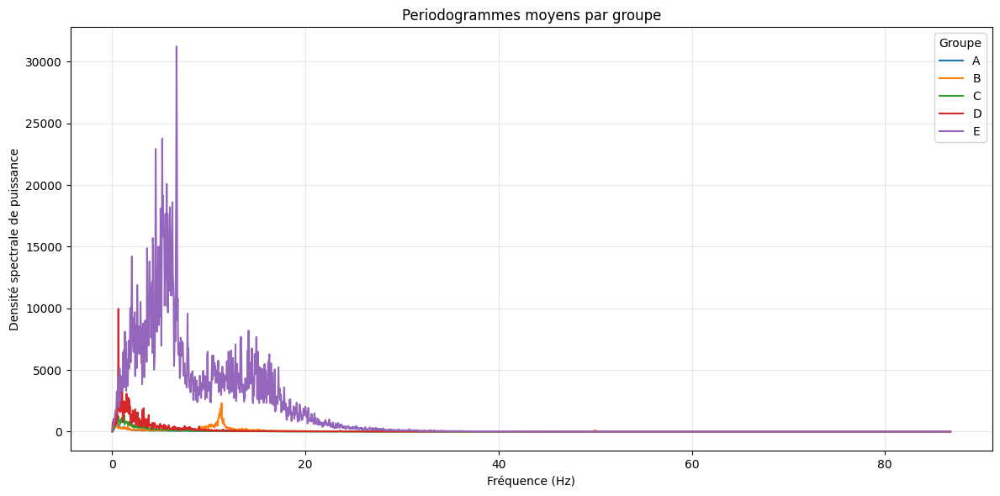

In [25]:
plot_periodograms(data, fs=fs, echelle ="lin")

In [26]:

def plot_periodograms(data, fs=200, bande=None,
                     echelle="semilogy", alpha=0.1):
    """
    Plot all individual periodograms, using one color per group.

    Parameters
    ----------
    data : dict
        Dictionary mapping group labels to arrays of shape
        (n_signals, n_samples).
    fs : float
        Sampling frequency in Hz.
    bande : tuple of float, optional
        Frequency range (f_min, f_max) to display, in Hz.
    echelle : str
        Plot scale:
        - "lin"      : linear x and y axes
        - "semilogx" : logarithmic x-axis, linear y-axis
        - "semilogy" : linear x-axis, logarithmic y-axis
        - "loglog"   : logarithmic x and y axes
    alpha : float
        Curve transparency, between 0 and 1.
    """
    echelles_valides = ("lin", "semilogx", "semilogy", "loglog")

    if echelle not in echelles_valides:
        raise ValueError(
            f"echelle must be one of {echelles_valides}"
        )

    fig, ax = plt.subplots(figsize=(10, 6))
    cmap = plt.get_cmap("tab10")

    for i, (lettre, tab) in enumerate(data.items()):

        # Compute one periodogram per signal (one row per signal)
        f, Pxx = periodogram(
            tab,
            fs=fs,
            detrend="constant",
            axis=-1
        )

        couleur = cmap(i)

        # Select the frequency range
        masque = np.ones_like(f, dtype=bool)

        if bande is not None:
            masque &= (f >= bande[0]) & (f <= bande[1])

        # Exclude zero frequencies when the x-axis is logarithmic
        if echelle in ("semilogx", "loglog"):
            masque &= f > 0

        # Plot every individual periodogram
        for j in range(Pxx.shape[0]):
            puissance = Pxx[j]
            masque_signal = masque.copy()

            # Logarithmic y-axis requires strictly positive power
            if echelle in ("semilogy", "loglog"):
                masque_signal &= puissance > 0

            kwargs = {
                "color": couleur,
                "alpha": alpha,
                "linewidth": 0.8,
                "label": lettre if j == 0 else None
            }

            if echelle == "lin":
                ax.plot(f[masque_signal], puissance[masque_signal],
                        **kwargs)

            elif echelle == "semilogx":
                ax.semilogx(f[masque_signal], puissance[masque_signal],
                            **kwargs)

            elif echelle == "semilogy":
                ax.semilogy(f[masque_signal], puissance[masque_signal],
                            **kwargs)

            elif echelle == "loglog":
                ax.loglog(f[masque_signal], puissance[masque_signal],
                          **kwargs)

    ax.set_xlabel("Fréquence [Hz]")
    ax.set_ylabel("DSP [µV²/Hz]")
    ax.set_title("Periodogrammes individuels par groupe")
    ax.legend(title="Groupe")
    ax.grid(True, which="both", alpha=0.25)

    fig.tight_layout()
    plt.show()


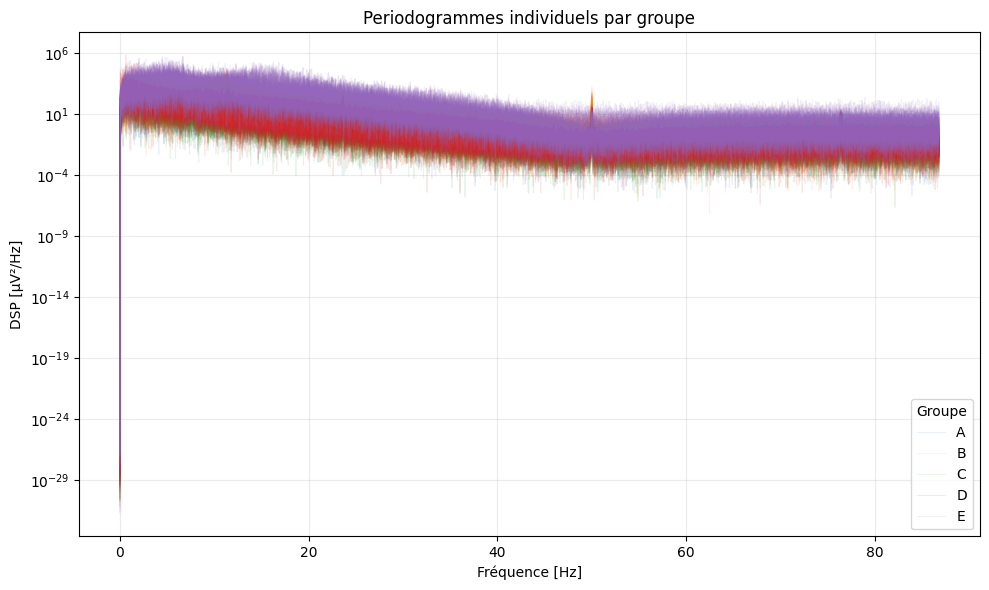

In [27]:
plot_periodograms(data, fs=fs, echelle ="semilogy")


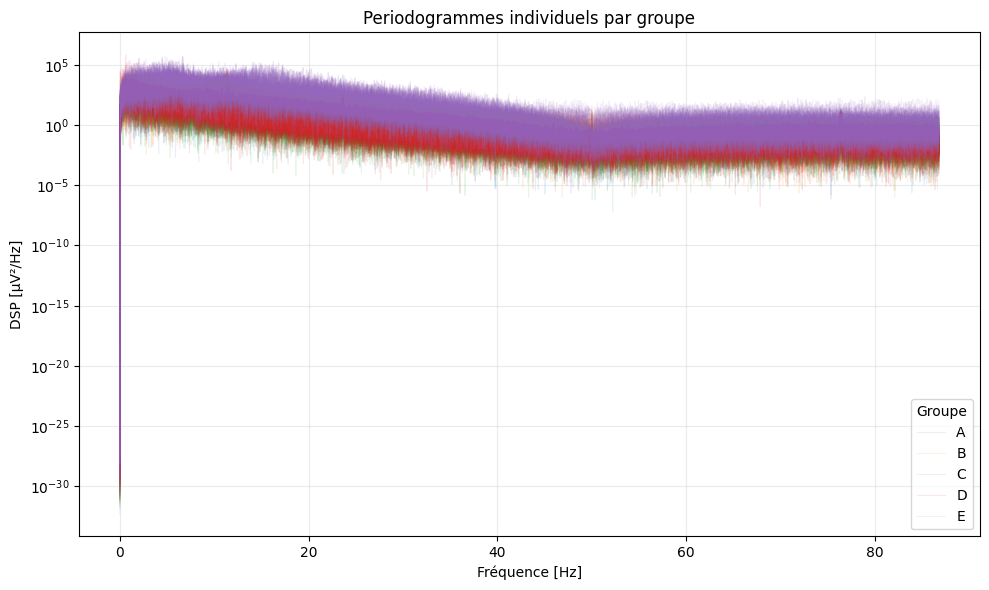

In [28]:
plot_periodograms(data_filtre, fs=fs, echelle ="semilogy")

In [29]:
import ruptures as rpt
from scipy import stats
from statsmodels.tsa.ar_model import AutoReg

In [30]:
def appliquer_fonction(data, fonction, parametres):
    """
    Apply a function to each group's signal array.

    Parameters
    ----------
    data : dict
        Dictionary mapping group labels to signal arrays.
    fonction : callable
        Function to apply. Its first argument must be the signal array.
    parametres : list or tuple
        Additional positional arguments passed to the function.

    Returns
    -------
    dict
        New dictionary containing the transformed signal arrays.
    """
    return {
        lettre: fonction(tab, *parametres)
        for lettre, tab in data.items()
    }

In [31]:

def analyser_ruptures(
    signal,
    Nk=10,
    min_size=10,
    afficher=True
):
    """
    Analyse un signal par détection de ruptures avec programmation dynamique.

    Parameters
    ----------
    signal : array-like
        Signal unidimensionnel à analyser.
    Nk : int, default=10
        Nombre maximal de ruptures à tester.
    min_size : int, default=3
        Nombre minimal d'échantillons par segment.
    afficher : bool, default=True
        Si True, affiche le coût en fonction du nombre de ruptures.

    Returns
    -------
    resultats : dict
        "n_bkps" : nombres de ruptures testés.
        "couts" : coûts totaux associés.
        "bkps" : positions des fins de segments pour chaque solution.
        "meilleur_n_bkps" : nombre de ruptures correspondant
                            au coude, ou None (choix indicatif).
    """

    # Mise en forme et vérification du signal
    x = np.asarray(signal, dtype=float).reshape(-1)

    if x.size < 2 * min_size:
        raise ValueError(
            "Le signal est trop court pour effectuer cette analyse."
        )

    if not np.all(np.isfinite(x)):
        raise ValueError(
            "Le signal contient des NaN ou des valeurs infinies."
        )

    if Nk < 1 or min_size < 1:
        raise ValueError("Nk et min_size doivent être positifs.")

    # ruptures attend un tableau (n_samples, n_features)
    x = x.reshape(-1, 1)

    # Nombre maximal de ruptures compatible avec min_size
    n_max = min(Nk, len(x) // min_size - 1)

    # Coût quadratique et algorithme de segmentation
    cout_l2 = rpt.costs.CostL2().fit(x)
    algo = rpt.Dynp(
        model="l2",
        min_size=min_size
    ).fit(x)

    n_bkps = np.arange(1, n_max + 1)
    couts = np.zeros(n_max)
    bkps = {}

    # Calcul des segmentations et de leurs coûts
    for i, n in enumerate(n_bkps):
        positions = algo.predict(n_bkps=int(n))
        bkps[int(n)] = positions
        couts[i] = cout_l2.sum_of_costs(positions)

        print(
            f"{n} rupture(s) : "
            f"positions = {positions}, "
            f"coût = {couts[i]:.4f}"
        )

    # Estimation indicative du coude de la courbe
    meilleur_n_bkps = None

    if len(couts) >= 3:
        ameliorations = couts[:-1] - couts[1:]
        diminutions = ameliorations[:-1] - ameliorations[1:]

        if len(diminutions) > 0:
            meilleur_n_bkps = int(
                n_bkps[1:-1][np.argmax(diminutions)]
            )

    # Affichage de la fonction objectif
    if afficher:
        plt.figure(
            "Fonction objectif selon le nombre de ruptures"
        )
        plt.plot(n_bkps, couts, marker="o")
        plt.xlabel("Nombre de ruptures")
        plt.ylabel("Coût total L2")
        plt.title("Détection de ruptures")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    return {
        "n_bkps": n_bkps,
        "couts": couts,
        "bkps": bkps,
        "meilleur_n_bkps": meilleur_n_bkps
    }

In [32]:
def corriger_tendance_ruptures(
    signal,
    fs=174.0,
    Nk=10,
    n_bkps=None,
    min_size=10,
    mode="trend",
    afficher=True
):
    """
    Detect change points using analyser_ruptures(), fit a linear
    trend on each segment, and subtract the piecewise trend.

    Parameters
    ----------
    signal : array-like
        One-dimensional input signal.
    fs : float, default=1.0
        Sampling frequency in Hz.
    Nk : int, default=10
        Maximum number of breakpoints tested by analyser_ruptures().
    n_bkps : int or None, default=None
        Number of breakpoints to use. If None, use the number
        suggested by analyser_ruptures()'s elbow heuristic.
    min_size : int, default=3
        Minimum segment length, passed to analyser_ruptures().
    mode : {"trend", "residual"}, default="trend"
        "trend": subtract the estimated piecewise trend.
        "residual": subtract the trend and restore the global mean.
    afficher : bool, default=True
        Whether to plot the original signal, trend, and corrected signal.

    Returns
    -------
    resultats : dict
        Original signal, estimated trend, corrected signal,
        selected breakpoints, and analysis results.
    """

    x = np.asarray(signal, dtype=float).reshape(-1)

    if x.size == 0 or not np.all(np.isfinite(x)):
        raise ValueError("Le signal doit être non vide et fini.")

    if fs <= 0:
        raise ValueError("fs doit être strictement positif.")

    if mode not in ("trend", "residual"):
        raise ValueError("mode doit être 'trend' ou 'residual'.")

    # 1. Detect breakpoints using the previous function
    analyse = analyser_ruptures(
        signal=x,
        Nk=Nk,
        min_size=min_size,
        afficher=False
    )

    # 2. Choose the number of breakpoints
    if n_bkps is None:
        n_bkps = analyse["meilleur_n_bkps"]

        if n_bkps is None:
            n_bkps = 1

    if n_bkps not in analyse["bkps"]:
        raise ValueError(
            f"n_bkps doit être compris entre 1 et "
            f"{len(analyse['n_bkps'])}."
        )

    ruptures = analyse["bkps"][n_bkps]

    # 3. Fit a linear trend independently on each segment
    temps = np.arange(len(x)) / fs
    tendance = np.empty_like(x)
    debut = 0

    for fin in ruptures:
        indices = np.arange(debut, fin)

        coefficients = np.polyfit(
            temps[indices],
            x[indices],
            deg=1
        )

        tendance[indices] = np.polyval(
            coefficients,
            temps[indices]
        )

        debut = fin

    # 4. Subtract the estimated trend
    signal_corrige = x - tendance

    if mode == "residual":
        signal_corrige += np.mean(x)

    # 5. Display the results
    if afficher:
        fig, axes = plt.subplots(
            2, 1, figsize=(12, 7), sharex=True
        )

        axes[0].plot(temps, x, label="Signal original")
        axes[0].plot(
            temps, tendance, label="Tendance estimée"
        )

        for point in ruptures[:-1]:
            axes[0].axvline(
                point / fs, linestyle="--", alpha=0.6
            )

        axes[0].set_ylabel("Amplitude")
        axes[0].legend()
        axes[0].grid(True)

        axes[1].plot(
            temps, signal_corrige, label="Signal corrigé"
        )
        axes[1].set_xlabel("Temps (s)")
        axes[1].set_ylabel("Amplitude")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()

    return signal_corrige

In [71]:
data_detrend = appliquer_fonction(data_filtre, corriger_tendance_ruptures, [])


1 rupture(s) : positions = [241510, 409700], coût = 946437973.9159


KeyboardInterrupt: 

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import ruptures as rpt
from functools import partial
from joblib import Parallel, delayed
from scipy.signal import decimate

In [31]:
def appliquer_fonction(data, fonction, parametres=(), n_jobs=1):
    """
    Applique `fonction` au signal de chaque groupe.

    Parameters
    ----------
    data : dict
        Dictionnaire {étiquette: tableau de signal}.
    fonction : callable
        Premier argument = tableau du signal.
    parametres : list or tuple
        Arguments positionnels supplémentaires.
    n_jobs : int, default=1
        1 = séquentiel, -1 = tous les coeurs (joblib).
        Utiliser afficher=False dans la fonction si n_jobs != 1.

    Returns
    -------
    dict
        {étiquette: résultat}
    """
    cles = list(data.keys())
    if n_jobs == 1:
        resultats = [fonction(data[k], *parametres) for k in cles]
    else:
        resultats = Parallel(n_jobs=n_jobs)(
            delayed(fonction)(data[k], *parametres) for k in cles
        )
    return dict(zip(cles, resultats))

In [32]:
def analyser_ruptures(
    signal, Nk=10, min_size=10, jump=5, afficher=True, verbose=False
):
    """
    Détection de ruptures par programmation dynamique (coût L2).

    Parameters
    ----------
    signal : array-like
        Signal unidimensionnel.
    Nk : int, default=10
        Nombre maximal de ruptures testées.
    min_size : int, default=10
        Taille minimale d'un segment (en échantillons).
    jump : int, default=5
        Les ruptures sont cherchées sur une grille de pas `jump`
        (plus grand = plus rapide, moins précis).
    afficher : bool, default=True
        Trace le coût en fonction du nombre de ruptures.
    verbose : bool, default=False
        Affiche les positions et coûts de chaque solution.

    Returns
    -------
    dict avec "n_bkps", "couts", "bkps", "meilleur_n_bkps" (coude, indicatif).
    """
    x = np.asarray(signal, dtype=float).reshape(-1)

    if Nk < 1 or min_size < 1 or jump < 1:
        raise ValueError("Nk, min_size et jump doivent être >= 1.")
    if not np.all(np.isfinite(x)):
        raise ValueError("Le signal contient des NaN ou des valeurs infinies.")

    pas = max(min_size, jump)
    if x.size < 2 * pas:
        raise ValueError("Le signal est trop court pour cette analyse.")

    x = x.reshape(-1, 1)
    n_max = min(Nk, len(x) // pas - 1)

    cout_l2 = rpt.costs.CostL2().fit(x)
    algo = rpt.Dynp(model="l2", min_size=min_size, jump=jump).fit(x)

    n_ok, couts, bkps = [], [], {}
    for n in range(1, n_max + 1):
        try:
            positions = algo.predict(n_bkps=n)
        except rpt.exceptions.BadSegmentationParameters:
            continue  # combinaison n / min_size / jump impossible
        n_ok.append(n)
        bkps[n] = positions
        couts.append(cout_l2.sum_of_costs(positions))
        if verbose:
            print(f"{n} rupture(s) : positions = {positions}, coût = {couts[-1]:.4f}")

    if not n_ok:
        raise ValueError("Aucune segmentation valide trouvée.")

    n_bkps = np.array(n_ok)
    couts = np.array(couts)

    # Coude : plus forte diminution du gain marginal
    meilleur_n_bkps = None
    if len(couts) >= 3:
        ameliorations = couts[:-1] - couts[1:]
        diminutions = ameliorations[:-1] - ameliorations[1:]
        meilleur_n_bkps = int(n_bkps[1:-1][np.argmax(diminutions)])

    if afficher:
        plt.figure("Fonction objectif selon le nombre de ruptures")
        plt.plot(n_bkps, couts, marker="o")
        plt.xlabel("Nombre de ruptures")
        plt.ylabel("Coût total L2")
        plt.title("Détection de ruptures")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    return {
        "n_bkps": n_bkps,
        "couts": couts,
        "bkps": bkps,
        "meilleur_n_bkps": meilleur_n_bkps,
    }

In [33]:
def corriger_tendance_ruptures(
    signal,
    fs=174.0,
    Nk=10,
    n_bkps=None,
    min_size=10,
    jump=5,
    q=1,
    mode="detrend",
    afficher=True,
):
    """
    Détecte des ruptures, ajuste une droite par segment et la soustrait.

    Parameters
    ----------
    signal : array-like
        Signal unidimensionnel.
    fs : float, default=174.0
        Fréquence d'échantillonnage (Hz).
    Nk : int, default=10
        Nombre maximal de ruptures testées.
    n_bkps : int or None
        Nombre de ruptures retenu. None = coude (ou 1 à défaut).
    min_size : int, default=10
        Taille minimale d'un segment, en échantillons du signal d'origine.
    jump : int, default=5
        Pas de la grille de recherche des ruptures.
    q : int, default=1
        Facteur de sous-échantillonnage pour la détection uniquement
        (ex. q=4 : environ 16 fois plus rapide). La tendance est
        ajustée sur le signal complet.
    mode : {"detrend", "residual"}
        "detrend"  : signal - tendance par morceaux.
        "residual" : idem, puis ajoute la moyenne globale.
    afficher : bool, default=True
        Trace le signal, la tendance et le signal corrigé.

    Returns
    -------
    numpy.ndarray
        Signal corrigé (même longueur que le signal d'entrée).
    """
    x = np.asarray(signal, dtype=float).reshape(-1)

    if x.size == 0 or not np.all(np.isfinite(x)):
        raise ValueError("Le signal doit être non vide et fini.")
    if fs <= 0:
        raise ValueError("fs doit être strictement positif.")
    if mode not in ("detrend", "residual"):
        raise ValueError("mode doit être 'detrend' ou 'residual'.")
    if q < 1:
        raise ValueError("q doit être >= 1.")

    # 1. Détection (éventuellement sur signal décimé)
    if q > 1:
        x_det = decimate(x, q)
        min_size_det = max(2, int(np.ceil(min_size / q)))
    else:
        x_det = x
        min_size_det = max(2, min_size)

    analyse = analyser_ruptures(
        x_det, Nk=Nk, min_size=min_size_det, jump=jump,
        afficher=False, verbose=False,
    )

    # 2. Choix du nombre de ruptures
    if n_bkps is None:
        n_bkps = analyse["meilleur_n_bkps"] or 1

    if n_bkps not in analyse["bkps"]:
        raise ValueError(
            f"n_bkps doit appartenir à {sorted(analyse['bkps'])}."
        )

    ruptures = analyse["bkps"][n_bkps]
    if q > 1:
        ruptures = [r * q for r in ruptures[:-1]] + [len(x)]

    # 3. Droite d'ajustement par segment
    temps = np.arange(len(x)) / fs
    tendance = np.empty_like(x)
    debut = 0
    for fin in ruptures:
        idx = slice(debut, fin)
        coef = np.polyfit(temps[idx], x[idx], deg=1)
        tendance[idx] = np.polyval(coef, temps[idx])
        debut = fin

    # 4. Soustraction
    signal_corrige = x - tendance
    if mode == "residual":
        signal_corrige += np.mean(x)

    # 5. Affichage
    if afficher:
        fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
        axes[0].plot(temps, x, label="Signal original")
        axes[0].plot(temps, tendance, label="Tendance estimée")
        for point in ruptures[:-1]:
            axes[0].axvline(point / fs, linestyle="--", alpha=0.6)
        axes[0].set_ylabel("Amplitude")
        axes[0].legend()
        axes[0].grid(True)

        axes[1].plot(temps, signal_corrige, label="Signal corrigé")
        axes[1].set_xlabel("Temps (s)")
        axes[1].set_ylabel("Amplitude")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()

    return signal_corrige

In [34]:

import numpy as np
from joblib import Parallel, delayed


def traiter_groupe(signaux, fonction, parametres=()):
    """
    Traite indépendamment chaque signal d'un groupe.

    Un tableau de forme (n_signaux, n_echantillons) est traité
    ligne par ligne, sans concaténer les signaux.
    """
    signaux = np.asarray(signaux)

    if signaux.ndim == 1:
        return fonction(signaux, *parametres)

    if signaux.ndim != 2:
        raise ValueError(
            f"Forme inattendue : {signaux.shape}. "
            "Un signal 1D ou un lot 2D est attendu."
        )

    resultats = np.empty(signaux.shape, dtype=np.float64)

    for i in range(signaux.shape[0]):
        resultats[i] = fonction(signaux[i], *parametres)

    return resultats


def appliquer_fonction(data, fonction, parametres=(), n_jobs=1):
    """
    Applique une fonction à chaque signal de chaque groupe.
    Les groupes peuvent être traités en parallèle.
    """
    cles = list(data.keys())

    if n_jobs == 1:
        resultats = [
            traiter_groupe(data[k], fonction, parametres)
            for k in cles
        ]
    else:
        resultats = Parallel(
            n_jobs=n_jobs,
            backend="loky",
            pre_dispatch=n_jobs,
            batch_size=1,
        )(
            delayed(traiter_groupe)(
                data[k], fonction, parametres
            )
            for k in cles
        )

    return dict(zip(cles, resultats))


In [35]:

import os
import numpy as np
from tqdm.auto import tqdm

# Dossier persistant de sauvegarde
DOSSIER = "sauvegardes_detrend"
os.makedirs(DOSSIER, exist_ok=True)

# Sauvegarde atomique : évite de conserver un fichier incomplet
# si le programme s'interrompt pendant l'écriture.
def sauvegarder_segment(chemin, resultat):
    temporaire = chemin + ".tmp.npy"
    np.save(temporaire, resultat)
    os.replace(temporaire, chemin)


data_detrend = {}
total = sum(np.asarray(v).shape[0] for v in data_filtre.values())

with tqdm(total=total, desc="Correction des signaux", unit="segment") as barre:

    for classe, signaux in data_filtre.items():
        signaux = np.asarray(signaux)

        if signaux.ndim != 2:
            raise ValueError(
                f"{classe} : forme inattendue {signaux.shape}"
            )

        n_signaux, n_points = signaux.shape
        resultats = np.empty((n_signaux, n_points), dtype=np.float64)

        # Un fichier par segment : on peut reprendre précisément
        # les segments non encore sauvegardés.
        dossier_classe = os.path.join(DOSSIER, str(classe))
        os.makedirs(dossier_classe, exist_ok=True)

        for i in range(n_signaux):
            chemin = os.path.join(
                dossier_classe, f"segment_{i:04d}.npy"
            )

            if os.path.exists(chemin):
                try:
                    resultat = np.load(chemin, allow_pickle=False)
                    if resultat.shape != (n_points,):
                        raise ValueError("Dimensions incorrectes")
                    resultats[i] = resultat
                    barre.update(1)
                    continue
                except (ValueError, OSError):
                    # Fichier incomplet ou invalide : recalculer
                    pass

            # Calcul du segment uniquement s'il n'est pas sauvegardé
            resultat = f(signaux[i])

            # Enregistrement immédiat du résultat
            sauvegarder_segment(chemin, resultat)
            resultats[i] = resultat
            barre.update(1)

        data_detrend[classe] = resultats

        print(f"Groupe {classe} terminé et récupérable sur disque.")

print("Tous les segments sont traités.")


Correction des signaux:   0%|          | 0/500 [00:00<?, ?segment/s]

TypeError: 'numpy.ndarray' object is not callable

In [38]:
# Application à tous les groupes (sans figures, en parallèle)
f = partial(
    corriger_tendance_ruptures,
    fs=174.0, Nk=10, n_bkps=None, min_size=1, jump=5, q=4,
    mode="detrend", afficher=False,
)

import os
import numpy as np
from functools import partial
from joblib import Parallel, delayed
from tqdm.auto import tqdm

# Paramètres
DOSSIER = os.path.abspath("sauvegardes_detrend")
N_JOBS = 4  # Commencer avec 2 pour limiter la RAM
os.makedirs(DOSSIER, exist_ok=True)

# Fonction de correction
fonction_detrend = partial(
    corriger_tendance_ruptures,
    fs=174.0,
    Nk=10,
    n_bkps=None,
    min_size=10,
    jump=15,
    q=4,
    mode="detrend",
    afficher=False,
)


def calculer_et_sauvegarder(classe, i, signal):
    """Calcule et sauvegarde un segment si nécessaire."""
    dossier_classe = os.path.join(DOSSIER, str(classe))
    os.makedirs(dossier_classe, exist_ok=True)

    chemin = os.path.join(dossier_classe, f"segment_{i:04d}.npy")

    # Vérifier si le résultat est déjà disponible
    if os.path.exists(chemin):
        try:
            resultat = np.load(chemin, allow_pickle=False)
            if resultat.shape == np.asarray(signal).shape:
                return i, resultat, False
        except (OSError, ValueError):
            pass

    # Calcul du segment
    resultat = fonction_detrend(signal)

    # Écriture temporaire puis remplacement atomique
    temporaire = chemin + ".tmp.npy"
    np.save(temporaire, resultat)
    os.replace(temporaire, chemin)

    return i, resultat, True


data_detrend = {}
total = sum(np.asarray(v).shape[0] for v in data_filtre.values())

with tqdm(total=total, desc="Correction EEG", unit="segment") as barre:
    for classe, signaux in data_filtre.items():
        signaux = np.asarray(signaux)

        if signaux.ndim != 2:
            raise ValueError(
                f"{classe}: forme attendue (n_segments, n_points), "
                f"reçue {signaux.shape}"
            )

        n_segments, n_points = signaux.shape
        resultats = np.empty((n_segments, n_points), dtype=np.float64)

        # Soumettre des tâches en parallèle avec une file limitée
        generateur = (
            delayed(calculer_et_sauvegarder)(classe, i, signaux[i])
            for i in range(n_segments)
        )

        taches = Parallel(
            n_jobs=N_JOBS,
            backend="loky",
            batch_size=1,
            pre_dispatch=N_JOBS,
            return_as="generator_unordered",
        )(generateur)

        for i, resultat, nouveau in taches:
            resultats[i] = resultat
            barre.update(1)

        data_detrend[classe] = resultats

print(f"Terminé. Résultats sauvegardés dans : {DOSSIER}")

#data_detrend = appliquer_fonction(data_filtre, f, n_jobs=4)

Correction EEG:   0%|          | 0/500 [00:00<?, ?segment/s]

Terminé. Résultats sauvegardés dans : /mnt/adisk/yassineferhi/traitement_signal/sauvegardes_detrend


In [39]:
# Nouvelle configuration, plus précise
N_JOBS = 2
DOSSIER = os.path.abspath("sauvegardes_detrend_v2")
os.makedirs(DOSSIER, exist_ok=True)

fonction_detrend = partial(
    corriger_tendance_ruptures,
    fs=174.0,
    Nk=10,
    n_bkps=None,
    min_size=10,
    jump=5,       # au lieu de 15
    q=2,          # au lieu de 4
    mode="detrend",
    afficher=False,
)
data_detrend = {}
total = sum(np.asarray(v).shape[0] for v in data_filtre.values())

with tqdm(total=total, desc="Correction EEG", unit="segment") as barre:
    for classe, signaux in data_filtre.items():
        signaux = np.asarray(signaux)

        if signaux.ndim != 2:
            raise ValueError(
                f"{classe}: forme attendue (n_segments, n_points), "
                f"reçue {signaux.shape}"
            )

        n_segments, n_points = signaux.shape
        resultats = np.empty((n_segments, n_points), dtype=np.float64)

        # Soumettre des tâches en parallèle avec une file limitée
        generateur = (
            delayed(calculer_et_sauvegarder)(classe, i, signaux[i])
            for i in range(n_segments)
        )

        taches = Parallel(
            n_jobs=N_JOBS,
            backend="loky",
            batch_size=1,
            pre_dispatch=N_JOBS,
            return_as="generator_unordered",
        )(generateur)

        for i, resultat, nouveau in taches:
            resultats[i] = resultat
            barre.update(1)

        data_detrend[classe] = resultats

print(f"Terminé. Résultats sauvegardés dans : {DOSSIER}")

#data_detrend = appliquer_fonction(data_filtre, f, n_jobs=4)

Correction EEG:   0%|          | 0/500 [00:00<?, ?segment/s]

Terminé. Résultats sauvegardés dans : /mnt/adisk/yassineferhi/traitement_signal/sauvegardes_detrend_v2


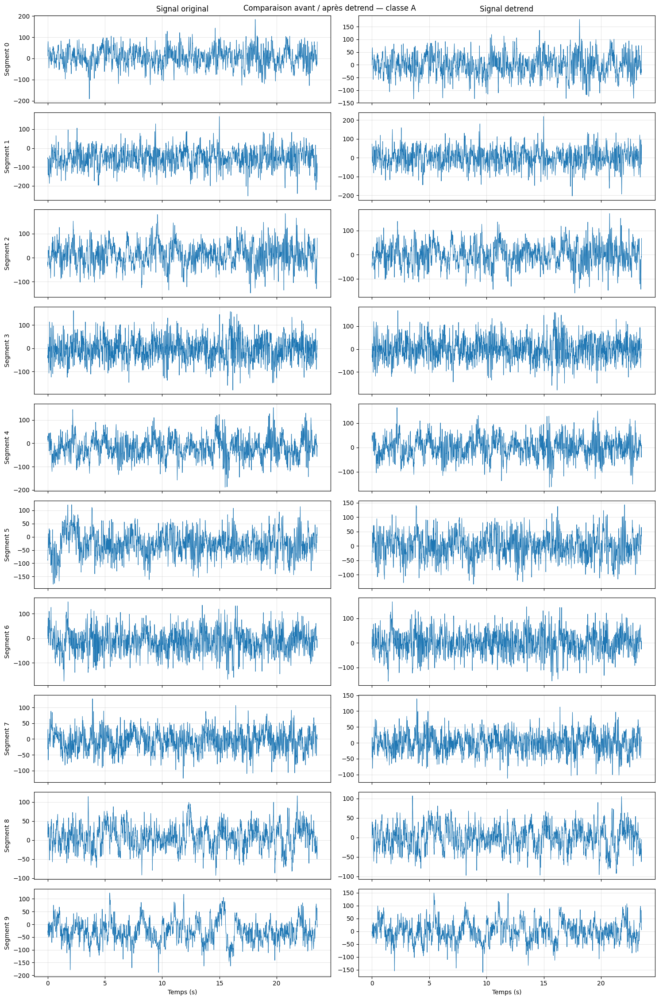

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Nombre de segments à afficher par classe
N = 10
fs = 174.0

# Choisir la classe à examiner
classe = "A"

originaux = np.asarray(data_filtre[classe])
corriges = np.asarray(data_detrend[classe])

n = min(N, len(originaux), len(corriges))
temps = np.arange(originaux.shape[1]) / fs

fig, axes = plt.subplots(
    n, 2,
    figsize=(15, 2.3 * n),
    sharex=True,
    squeeze=False,
)

for i in range(n):
    # Signal original
    axes[i, 0].plot(temps, originaux[i], linewidth=0.7)
    axes[i, 0].set_ylabel(f"Segment {i}")
    axes[i, 0].grid(True, alpha=0.3)

    # Signal detrend
    axes[i, 1].plot(temps, corriges[i], linewidth=0.7)
    axes[i, 1].grid(True, alpha=0.3)

axes[0, 0].set_title("Signal original")
axes[0, 1].set_title("Signal detrend")

axes[-1, 0].set_xlabel("Temps (s)")
axes[-1, 1].set_xlabel("Temps (s)")

plt.suptitle(f"Comparaison avant / après detrend — classe {classe}")
plt.tight_layout()
plt.show()

In [40]:
import os
import numpy as np
from scipy.signal import butter, sosfiltfilt
from tqdm.auto import tqdm

# ============================================================
# 1. Dossiers
# ============================================================

DOSSIER_SOURCE = os.path.abspath("sauvegardes_detrend_v2")
DOSSIER_SORTIE = os.path.abspath("detrend_filtre50_filtre1_80")

os.makedirs(DOSSIER_SORTIE, exist_ok=True)

# ============================================================
# 2. Filtre passe-bande 0,5–80 Hz
# ============================================================

fs = 174.0
sos = butter(
    4,
    (0.5, 80.0),
    btype="bandpass",
    fs=fs,
    output="sos"
)

# ============================================================
# 3. Charger, filtrer et sauvegarder
# ============================================================

data_filtre_v2 = {}

for classe in sorted(os.listdir(DOSSIER_SOURCE)):
    dossier_classe = os.path.join(DOSSIER_SOURCE, classe)

    if not os.path.isdir(dossier_classe):
        continue

    fichiers = sorted(
        f for f in os.listdir(dossier_classe)
        if f.startswith("segment_") and f.endswith(".npy")
    )

    if not fichiers:
        continue

    dossier_sortie_classe = os.path.join(DOSSIER_SORTIE, classe)
    os.makedirs(dossier_sortie_classe, exist_ok=True)

    # Préparer le dictionnaire de sortie
    segments_filtres = []

    for fichier in tqdm(fichiers, desc=f"Classe {classe}"):
        chemin_source = os.path.join(dossier_classe, fichier)
        chemin_sortie = os.path.join(dossier_sortie_classe, fichier)

        signal = np.load(chemin_source, allow_pickle=False)

        if os.path.exists(chemin_sortie):
            # Réutiliser le résultat déjà calculé
            signal_filtre = np.load(chemin_sortie, allow_pickle=False)
        else:
            signal_filtre = sosfiltfilt(sos, signal, axis=-1)

            # Sauvegarde atomique pour éviter un fichier incomplet
            temporaire = chemin_sortie + ".tmp.npy"
            np.save(temporaire, signal_filtre)
            os.replace(temporaire, chemin_sortie)

        segments_filtres.append(signal_filtre)

    data_filtre_v2[classe] = np.stack(segments_filtres)

    print(f"Classe {classe} : {data_filtre_v2[classe].shape}")

print(f"\nRésultats enregistrés dans : {DOSSIER_SORTIE}")

Classe A:   0%|          | 0/100 [00:00<?, ?it/s]

Classe A : (100, 4097)


Classe B:   0%|          | 0/100 [00:00<?, ?it/s]

Classe B : (100, 4097)


Classe C:   0%|          | 0/100 [00:00<?, ?it/s]

Classe C : (100, 4097)


Classe D:   0%|          | 0/100 [00:00<?, ?it/s]

Classe D : (100, 4097)


Classe E:   0%|          | 0/100 [00:00<?, ?it/s]

Classe E : (100, 4097)

Résultats enregistrés dans : /mnt/adisk/yassineferhi/traitement_signal/detrend_filtre50_filtre1_80


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Nombre de segments à afficher par classe
N = 10
fs = 174.0

# Choisir la classe à examiner
classe = "A"

originaux = np.asarray(data_filtre[classe])
corriges = np.asarray(data_filtre_v2[classe])

n = min(N, len(originaux), len(corriges))
temps = np.arange(originaux.shape[1]) / fs

fig, axes = plt.subplots(
    n, 2,
    figsize=(15, 2.3 * n),
    sharex=True,
    squeeze=False,
)

for i in range(n):
    # Signal original
    axes[i, 0].plot(temps, originaux[i], linewidth=0.7)
    axes[i, 0].set_ylabel(f"Segment {i}")
    axes[i, 0].grid(True, alpha=0.3)

    # Signal detrend
    axes[i, 1].plot(temps, corriges[i], linewidth=0.7)
    axes[i, 1].grid(True, alpha=0.3)

axes[0, 0].set_title("Signal original")
axes[0, 1].set_title("Signal detrend")

axes[-1, 0].set_xlabel("Temps (s)")
axes[-1, 1].set_xlabel("Temps (s)")

plt.suptitle(f"Comparaison avant / après detrend — classe {classe}")
plt.tight_layout()
plt.show()

In [37]:

from pathlib import Path
import subprocess
import tempfile

import numpy as np
from tqdm import tqdm


# ============================================================
# 1. PARAMÈTRES MODIFIABLES
# ============================================================

# Dossier contenant les segments EEG déjà filtrés
INPUT_DIR = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/"
    "detrend_filtre50_filtre1_80"
)

# Dossier où seront sauvegardés les résultats EMPI
OUTPUT_DIR = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/"
    "matching_pursuit_empi_80"
)

# Chemin du programme EMPI installé dans ton compte utilisateur
EMPI = Path.home() / "local" / "bin" / "empi"

# Fréquence d'échantillonnage du signal, en Hz
FS = 174.0

# Paramètres du Matching Pursuit
MAX_ITERATIONS = 80
RESIDUAL_ENERGY = 0.01
OPTIMIZATION = "global"

# Paramètres du dictionnaire de Gabor
GABOR_FREQ_MAX = 80.0  # Fréquence maximale des atomes, en Hz

# Ressources CPU
CPU_THREADS = 2
CPU_WORKERS = 1

# Si True, les atomes doivent rester entièrement dans le signal.
FULL_ATOMS_IN_SIGNAL = True

# Si True, un résultat déjà présent est ignoré.
RESUME = True

# Sauvegarder les données d'entrée temporaires en float64.
# Cela nécessite l'option --input64 d'EMPI.
USE_FLOAT64 = True


# ============================================================
# 2. VÉRIFICATIONS
# ============================================================

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(
        f"Dossier d'entrée introuvable : {INPUT_DIR}"
    )

if not EMPI.is_file():
    raise FileNotFoundError(
        f"Binaire EMPI introuvable : {EMPI}\n"
        "Vérifie le chemin avec : ~/local/bin/empi --version"
    )

if MAX_ITERATIONS < 1:
    raise ValueError("MAX_ITERATIONS doit être supérieur à 0.")

if not 0 < RESIDUAL_ENERGY <= 1:
    raise ValueError("RESIDUAL_ENERGY doit être entre 0 et 1.")

if CPU_THREADS < 1 or CPU_WORKERS < 1:
    raise ValueError("Les paramètres CPU doivent être positifs.")


# ============================================================
# 3. TROUVER LES SEGMENTS
# ============================================================

segments = sorted(INPUT_DIR.glob("*/*.npy"))

if not segments:
    raise FileNotFoundError(
        f"Aucun fichier .npy trouvé dans {INPUT_DIR}/<classe>/"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Nombre de segments trouvés : {len(segments)}")
print(f"Résultats sauvegardés dans : {OUTPUT_DIR}")


# ============================================================
# 4. TRAITER UN SEGMENT AVEC EMPI
# ============================================================

def run_matching_pursuit(segment_path: Path) -> str:
    """
    Applique Matching Pursuit avec le dictionnaire de Gabor d'EMPI.

    Le résultat est sauvegardé en JSON, un fichier par segment.
    Retourne le statut du traitement.
    """

    # Préserver l'organisation des classes
    relative_path = segment_path.relative_to(INPUT_DIR)
    output_path = (OUTPUT_DIR / relative_path).with_suffix(".json")
    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Reprise : ne pas recalculer un résultat déjà sauvegardé
    if (
        RESUME
        and output_path.is_file()
        and output_path.stat().st_size > 0
    ):
        return "ignoré"

    # Charger le signal
    signal = np.load(segment_path, allow_pickle=False)
    signal = np.asarray(signal).squeeze()

    if signal.ndim != 1:
        raise ValueError(
            f"Le segment doit être un signal 1D, forme obtenue : "
            f"{signal.shape}"
        )

    if signal.size == 0:
        raise ValueError("Le segment est vide.")

    if not np.all(np.isfinite(signal)):
        raise ValueError("Le segment contient des NaN ou des infinis.")

    dtype = np.float64 if USE_FLOAT64 else np.float32
    signal = np.asarray(signal, dtype=dtype)

    # EMPI lit un fichier binaire brut, pas un fichier .npy
    with tempfile.NamedTemporaryFile(suffix=".bin") as temp_file:
        signal.tofile(temp_file.name)

        command = [
            str(EMPI),
            temp_file.name,
            str(output_path),
            "-f", str(FS),
            "-i", str(MAX_ITERATIONS),
            "-r", str(RESIDUAL_ENERGY),
            "-o", OPTIMIZATION,
            "--gabor",
            "--gabor-freq-max", str(GABOR_FREQ_MAX),
            "--cpu-threads", str(CPU_THREADS),
            "--cpu-workers", str(CPU_WORKERS),
        ]

        if USE_FLOAT64:
            command.append("--input64")

        if FULL_ATOMS_IN_SIGNAL:
            command.append("--full-atoms-in-signal")

        # Conserver la sortie détaillée d'EMPI en cas de problème
        log_path = output_path.with_suffix(".log")

        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=None,
        )

    if result.returncode != 0:
        # Ne pas conserver un JSON incomplet comme résultat valide
        if output_path.exists():
            output_path.unlink()

        log_path.write_text(
            "COMMANDE :\n"
            + " ".join(command)
            + "\n\nSTDOUT :\n"
            + result.stdout
            + "\n\nSTDERR :\n"
            + result.stderr,
            encoding="utf-8",
        )

        return "erreur"

    # Sauvegarder les messages seulement si EMPI en a produit
    if result.stdout.strip() or result.stderr.strip():
        log_path.write_text(
            "STDOUT :\n"
            + result.stdout
            + "\n\nSTDERR :\n"
            + result.stderr,
            encoding="utf-8",
        )

    if not output_path.is_file() or output_path.stat().st_size == 0:
        log_path.write_text(
            "EMPI s'est terminé sans erreur, mais aucun JSON "
            "non vide n'a été créé.\n"
            + result.stdout
            + "\n"
            + result.stderr,
            encoding="utf-8",
        )
        return "erreur"

    return "réussi"


# ============================================================
# 5. BOUCLE AVEC BARRE DE PROGRESSION ET REPRISE
# ============================================================

counts = {
    "réussi": 0,
    "ignoré": 0,
    "erreur": 0,
}

errors = []

for segment_path in tqdm(segments, desc="Matching Pursuit", unit="segment"):
    try:
        status = run_matching_pursuit(segment_path)
    except Exception as exc:
        status = "erreur"
        print(f"\nErreur sur {segment_path} : {exc}")

    counts[status] += 1

    if status == "erreur":
        errors.append(str(segment_path))

print("\nTraitement terminé.")
print(f"Segments traités : {counts['réussi']}")
print(f"Segments ignorés (déjà présents) : {counts['ignoré']}")
print(f"Erreurs : {counts['erreur']}")

if errors:
    print("\nSegments en erreur :")
    for path in errors:
        print(f" - {path}")


Nombre de segments trouvés : 500
Résultats sauvegardés dans : /mnt/adisk/yassineferhi/traitement_signal/matching_pursuit_empi_80


Matching Pursuit: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 500/500 [14:31<00:00,  1.74s/segment]


Traitement terminé.
Segments traités : 500
Segments ignorés (déjà présents) : 0
Erreurs : 0


In [38]:
import numpy as np
import matplotlib.pyplot as plt

N = 10
fs = 174.0
classe = "A"

# Signaux originaux
originaux = np.asarray(data_filtre[classe])

# Noms des segments Matching Pursuit
noms_segments = sorted(matching_pursuit[classe].keys())

print("Structure d'un résultat :")
print(type(matching_pursuit[classe][noms_segments[0]]))
print(str(matching_pursuit[classe][noms_segments[0]])[:1000])

Structure d'un résultat :
<class 'dict'>
{'version': '1.0.4', 'channel_count': 1, 'sampling_frequency_Hz': 174, 'segments': [{'sample_count': 4097, 'segment_length_s': 23.5459770114943, 'segment_offset_s': 0, 'channels': [{'atoms': [{'amplitude': 51.75151, 'energy': 1944.5777, 'envelope': 'gauss', 'f_Hz': 11.565274, 'phase': 3.0262355, 'scale_s': 2.0536398, 't0_s': 18.16092, 't0_abs_s': 18.16092}, {'amplitude': 38.71619, 'energy': 2397.2791, 'envelope': 'gauss', 'f_Hz': 0.70493489, 'phase': 2.4478946, 'scale_s': 4.5235398, 't0_s': 19.992206, 't0_abs_s': 19.992206}, {'amplitude': 108.2075, 'energy': 1173.9709, 'envelope': 'gauss', 'f_Hz': 3.6913115, 'phase': -2.0008132, 'scale_s': 0.28377551, 't0_s': 17.233963, 't0_abs_s': 17.233963}, {'amplitude': 25.989106, 'energy': 1051.796, 'envelope': 'gauss', 'f_Hz': 1.0076114, 'phase': -0.57256359, 'scale_s': 4.4044722, 't0_s': 11.445016, 't0_abs_s': 11.445016}, {'amplitude': 63.809893, 'energy': 1159.9727, 'envelope': 'gauss', 'f_Hz': 11.222074

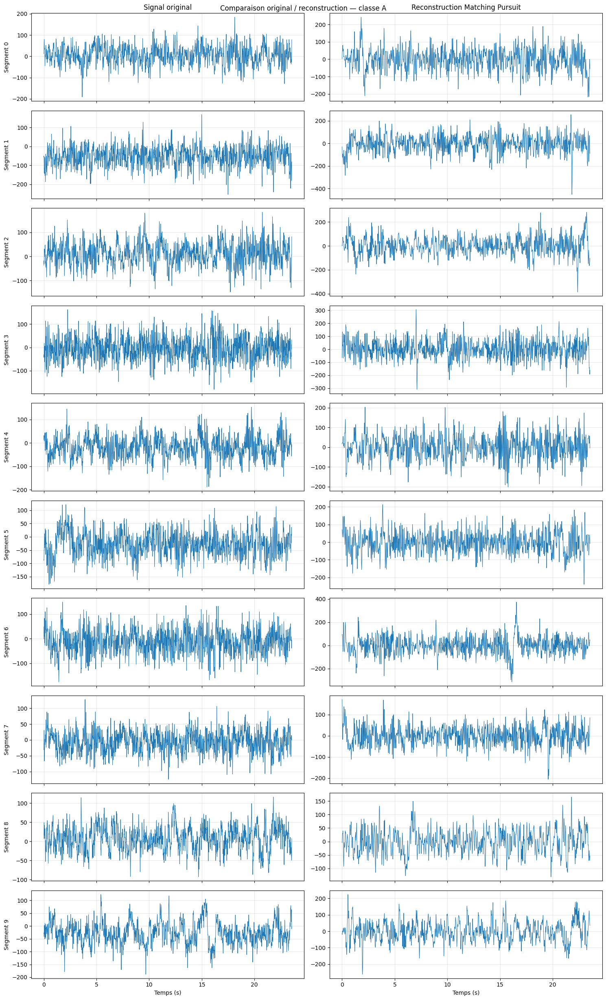

In [39]:

import numpy as np
import matplotlib.pyplot as plt

# Paramètres
N = 10
fs = 174.0
classe = "A"

# Signaux originaux
originaux = np.asarray(data_filtre[classe])

# Temps associé à un segment
temps = np.arange(originaux.shape[1]) / fs

# Récupérer les noms de fichiers dans l'ordre
noms_segments = sorted(matching_pursuit[classe].keys())

# Limiter aux segments disponibles des deux côtés
n = min(N, len(originaux), len(noms_segments))

# Reconstruire un segment à partir des atomes exportés
def reconstruire_segment(resultat, fs, n_samples):
    t = np.arange(n_samples) / fs
    signal_reconstruit = np.zeros(n_samples, dtype=float)

    atomes = resultat["segments"][0]["channels"][0]["atoms"]

    for atome in atomes:
        A = atome["amplitude"]
        f = atome["f_Hz"]
        phase = atome["phase"]
        t0 = atome["t0_s"]
        scale = atome["scale_s"]

        # Enveloppe gaussienne (convention à confirmer)
        enveloppe = np.exp(-0.5 * ((t - t0) / scale) ** 2)

        oscillation = np.cos(2 * np.pi * f * (t - t0) + phase)

        signal_reconstruit += A * enveloppe * oscillation

    return signal_reconstruit


fig, axes = plt.subplots(
    n, 2,
    figsize=(15, 2.5 * n),
    sharex=True,
    squeeze=False,
)

for i in range(n):
    resultat = matching_pursuit[classe][noms_segments[i]]
    reconstruit = reconstruire_segment(resultat, fs, originaux.shape[1])

    axes[i, 0].plot(temps, originaux[i], linewidth=0.7)
    axes[i, 0].set_ylabel(f"Segment {i}")
    axes[i, 0].grid(True, alpha=0.3)

    axes[i, 1].plot(temps, reconstruit, linewidth=0.7)
    axes[i, 1].grid(True, alpha=0.3)

axes[0, 0].set_title("Signal original")
axes[0, 1].set_title("Reconstruction Matching Pursuit")

axes[-1, 0].set_xlabel("Temps (s)")
axes[-1, 1].set_xlabel("Temps (s)")

plt.suptitle(f"Comparaison original / reconstruction — classe {classe}")
plt.tight_layout()
plt.show()


In [40]:
import json
import numpy as np

def load_atoms(json_path):
    with open(json_path) as f:
        d = json.load(f)
    seg = d["segments"][0]
    return seg["sample_count"], d["sampling_frequency_Hz"], seg["channels"][0]["atoms"]

def synth(atoms, n, fs, phase_at_t0=True):
    t = np.arange(n) / fs
    x = np.zeros(n)
    for a in atoms:
        dt = t - a["t0_s"]
        env = np.exp(-np.pi * (dt / a["scale_s"]) ** 2)
        arg = 2 * np.pi * a["f_Hz"] * (dt if phase_at_t0 else t) + a["phase"]
        x += a["amplitude"] * env * np.cos(arg)
    return x

def select_atoms(atoms, scale_min_s=0.05, f_min=None, f_max=None, e_sigma=None):
    keep, rejected = [], []
    e = np.array([a["energy"] for a in atoms])
    if e_sigma is not None:
        med = np.median(e)
        mad = 1.4826 * np.median(np.abs(e - med))
        e_max = med + e_sigma * mad
    for a in atoms:
        bad = a["scale_s"] < scale_min_s
        if f_min is not None and a["f_Hz"] < f_min: bad = True
        if f_max is not None and a["f_Hz"] > f_max: bad = True
        if e_sigma is not None and a["energy"] > e_max and a["scale_s"] < 0.2:
            bad = True   # atome énergétique ET court = suspect
        (rejected if bad else keep).append(a)
    return keep, rejected

def rel_err(x, y):
    return np.linalg.norm(x - y) / np.linalg.norm(x)

In [42]:
from pathlib import Path
import numpy as np

INPUT_DIR = Path("/mnt/adisk/yassineferhi/traitement_signal/detrend_filtre50_filtre1_80")
OUTPUT_DIR = Path("/mnt/adisk/yassineferhi/traitement_signal/matching_pursuit_empi_80")

# Premier segment trouvé (ou remplace par un segment précis, par ex. celui avec une impulsion)
npy_path = sorted(INPUT_DIR.glob("*/*.npy"))[0]
json_path = (OUTPUT_DIR / npy_path.relative_to(INPUT_DIR)).with_suffix(".json")

print(npy_path)
print(json_path, json_path.is_file())

x = np.load(npy_path).squeeze()
n, fs, atoms = load_atoms(json_path)
# cohérence avec l'énergie résiduelle d'EMPI
print("somme énergies / énergie signal :",
      sum(a["energy"] for a in atoms) / (np.sum(x**2) / fs))
keep, rej = select_atoms(atoms, scale_min_s=0.05, e_sigma=None)
x_sparse = synth(keep, n, fs)
x_spikes = synth(rej, n, fs)
print(len(keep), "gardés,", len(rej), "rejetés")

/mnt/adisk/yassineferhi/traitement_signal/detrend_filtre50_filtre1_80/A/segment_0000.npy
/mnt/adisk/yassineferhi/traitement_signal/matching_pursuit_empi_80/A/segment_0000.json True
somme énergies / énergie signal : 0.7879129369392446
79 gardés, 1 rejetés


phase en t0 0.4597163858853301
phase en 0 39.849344660272735
erreur attendue ≈ 0.4604345773288535
rejeté : t0=0.025s  f=0.0Hz  échelle=48ms  amp=7789.7


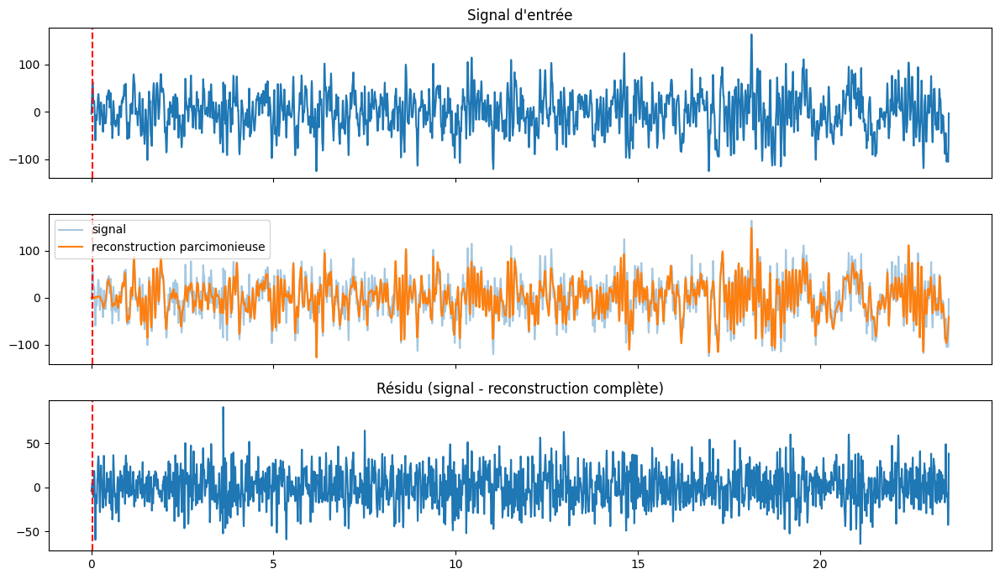

In [43]:
import matplotlib.pyplot as plt

# 1. Test des deux conventions de phase
for p0 in (True, False):
    r = synth(atoms, n, fs, phase_at_t0=p0)
    print("phase en t0" if p0 else "phase en 0", rel_err(x, r))
print("erreur attendue ≈", np.sqrt(1 - 0.788))

# 2. Reconstruction complète, résidu, atome rejeté
full = synth(atoms, n, fs)           # adapte phase_at_t0 selon le test
keep, rej = select_atoms(atoms, scale_min_s=0.05)
x_sparse = synth(keep, n, fs)
x_rej = synth(rej, n, fs)
resid = x - full

for a in rej:
    print(f"rejeté : t0={a['t0_s']:.3f}s  f={a['f_Hz']:.1f}Hz  "
          f"échelle={a['scale_s']*1000:.0f}ms  amp={a['amplitude']:.1f}")

# 3. Tracé
t = np.arange(n) / fs
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(t, x); ax[0].set_title("Signal d'entrée")
ax[1].plot(t, x, alpha=.4, label="signal"); ax[1].plot(t, x_sparse, label="reconstruction parcimonieuse")
ax[1].legend()
ax[2].plot(t, resid); ax[2].set_title("Résidu (signal - reconstruction complète)")
for a in rej:
    for axis in ax: axis.axvline(a["t0_s"], color="r", ls="--")
plt.tight_layout(); plt.show()

In [44]:
a = rej[0]
print("énergie de l'atome rejeté :", a["energy"],
      "| énergie totale des atomes :", sum(b["energy"] for b in atoms))

print("5 premiers/derniers échantillons :", x[:5], x[-5:])
print("max |x| au bord (0.3 s) vs au centre :",
      np.abs(x[:52]).max(), np.abs(x[52:-52]).max())

# erreur sur la partie centrale, hors bords
m = slice(52, -52)
print("err. relative hors bords (0.3 s) :", rel_err(x[m], full[m]))
print("err. relative reconstruction parcimonieuse hors bords :", rel_err(x[m], x_sparse[m]))

énergie de l'atome rejeté : 114.4656 | énergie totale des atomes : 29888.07529
5 premiers/derniers échantillons : [-3.82545917  5.54290156 19.5040702  30.17231145 52.44073596] [ -99.88318654 -105.41681064  -91.33172754  -71.7759474    -3.06442926]
max |x| au bord (0.3 s) vs au centre : 63.98595638968204 163.79927031030283
err. relative hors bords (0.3 s) : 0.46085211771589696
err. relative reconstruction parcimonieuse hors bords : 0.46085211771589696


In [45]:
   bad = (a["f_Hz"] < 1.0                       # sous la bande du filtre
          or a["t0_s"] < 0.3                    # trop près du bord
          or a["t0_s"] > seg_len - 0.3
          or a["scale_s"] < 0.05)

In [46]:
import numpy as np
from pathlib import Path

def spike_score(x):
    med = np.median(x)
    mad = 1.4826 * np.median(np.abs(x - med))
    return np.max(np.abs(x - med)) / mad

scores = []
for p in sorted(INPUT_DIR.glob("*/*.npy")):
    x = np.load(p).squeeze()
    scores.append((spike_score(x), p))

scores.sort(reverse=True)
for s, p in scores[:15]:
    print(f"{s:6.1f}  {p.relative_to(INPUT_DIR)}")

  15.8  D/segment_0008.npy
  14.1  D/segment_0075.npy
  14.0  D/segment_0001.npy
  13.5  D/segment_0040.npy
  13.2  D/segment_0009.npy
  12.6  D/segment_0028.npy
  12.2  D/segment_0029.npy
  11.7  D/segment_0071.npy
  11.6  D/segment_0007.npy
   9.6  D/segment_0097.npy
   9.2  D/segment_0069.npy
   8.9  E/segment_0055.npy
   8.8  D/segment_0063.npy
   7.6  E/segment_0010.npy
   7.5  E/segment_0098.npy


err complète : 0.10290898318255126 | énergie expliquée : 0.9881618078492015
pic max à t = 10.21264367816092 s
t0=22.921s f=10.7Hz échelle=32ms énergie=48120
t0=22.927s f=51.9Hz échelle=32ms énergie=4969
t0=22.955s f=19.0Hz échelle=36ms énergie=1347
t0=5.371s f=25.2Hz échelle=51ms énergie=2465
t0=5.381s f=0.0Hz échelle=63ms énergie=108361
t0=1.963s f=1.3Hz échelle=67ms énergie=113800
t0=16.833s f=28.0Hz échelle=70ms énergie=1315
t0=0.755s f=1.1Hz échelle=72ms énergie=131364


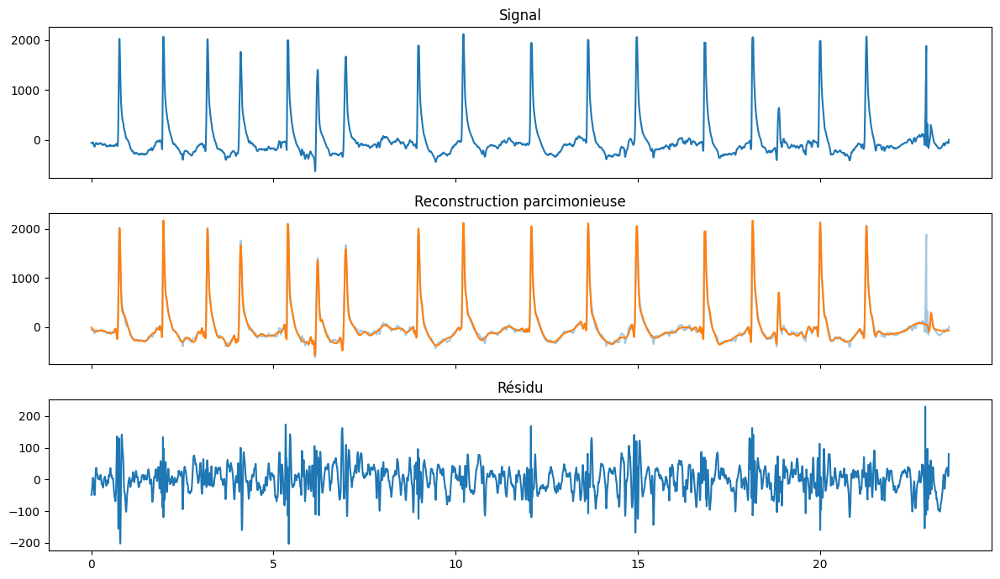

In [47]:
import matplotlib.pyplot as plt

npy_path = INPUT_DIR / "D" / "segment_0008.npy"
json_path = (OUTPUT_DIR / npy_path.relative_to(INPUT_DIR)).with_suffix(".json")
x = np.load(npy_path).squeeze()
n, fs, atoms = load_atoms(json_path)

full = synth(atoms, n, fs)
resid = x - full
keep, rej = select_atoms(atoms, scale_min_s=0.05)
x_sparse = synth(keep, n, fs)

print("err complète :", rel_err(x, full), "| énergie expliquée :",
      sum(a["energy"] for a in atoms) / (np.sum(x**2) / fs))
print("pic max à t =", np.argmax(np.abs(x)) / fs, "s")
for a in sorted(atoms, key=lambda a: a["scale_s"])[:8]:
    print(f"t0={a['t0_s']:.3f}s f={a['f_Hz']:.1f}Hz "
          f"échelle={a['scale_s']*1000:.0f}ms énergie={a['energy']:.0f}")

t = np.arange(n) / fs
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(t, x); ax[0].set_title("Signal")
ax[1].plot(t, x, alpha=.4); ax[1].plot(t, x_sparse); ax[1].set_title("Reconstruction parcimonieuse")
ax[2].plot(t, resid); ax[2].set_title("Résidu")
plt.tight_layout(); plt.show()

t0=5.371  f=25.2  éch=51ms  E=2465
t0=22.921  f=10.7  éch=32ms  E=48120
t0=22.927  f=51.9  éch=32ms  E=4969
t0=22.955  f=19.0  éch=36ms  E=1347


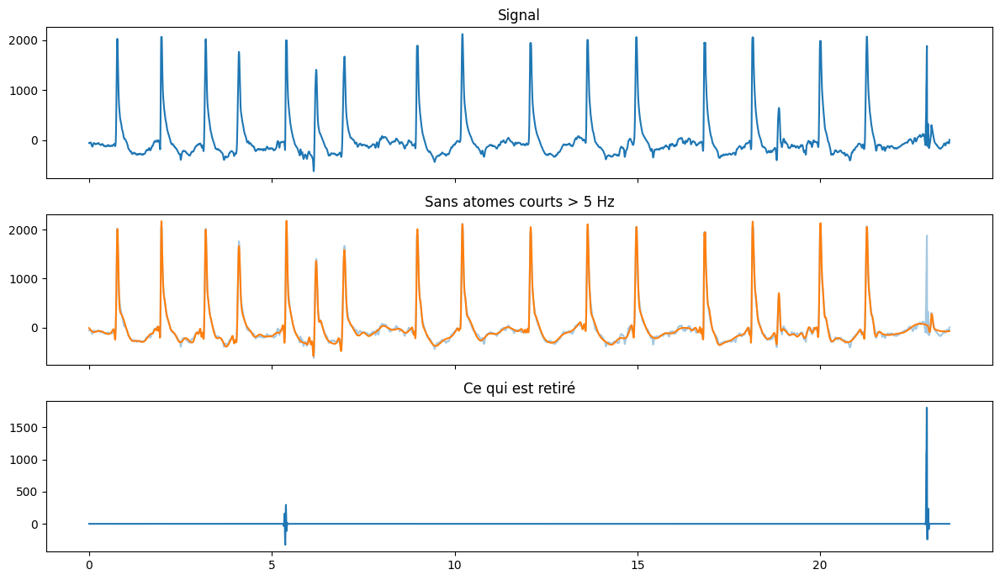

énergie retirée : 0.014508808662004723


In [48]:
# Atomes courts (< 60 ms) et de fréquence > 5 Hz, regroupés par position
sus = [a for a in atoms if a["scale_s"] < 0.06 and a["f_Hz"] > 5]
for a in sorted(sus, key=lambda a: a["t0_s"]):
    print(f"t0={a['t0_s']:.3f}  f={a['f_Hz']:.1f}  éch={a['scale_s']*1000:.0f}ms  E={a['energy']:.0f}")

keep2 = [a for a in atoms if a not in sus]
x_sparse2 = synth(keep2, n, fs)
x_removed = synth(sus, n, fs)

t = np.arange(n) / fs
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(t, x); ax[0].set_title("Signal")
ax[1].plot(t, x, alpha=.4); ax[1].plot(t, x_sparse2); ax[1].set_title("Sans atomes courts > 5 Hz")
ax[2].plot(t, x_removed); ax[2].set_title("Ce qui est retiré")
plt.tight_layout(); plt.show()

print("énergie retirée :", sum(a["energy"] for a in sus) / sum(a["energy"] for a in atoms))

Classes chargées : ['A', 'B', 'C', 'D', 'E']
Classe A : 100 segments
  Forme du premier segment : (4097,)
Classe B : 100 segments
  Forme du premier segment : (4097,)
Classe C : 100 segments
  Forme du premier segment : (4097,)
Classe D : 100 segments
  Forme du premier segment : (4097,)
Classe E : 100 segments
  Forme du premier segment : (4097,)


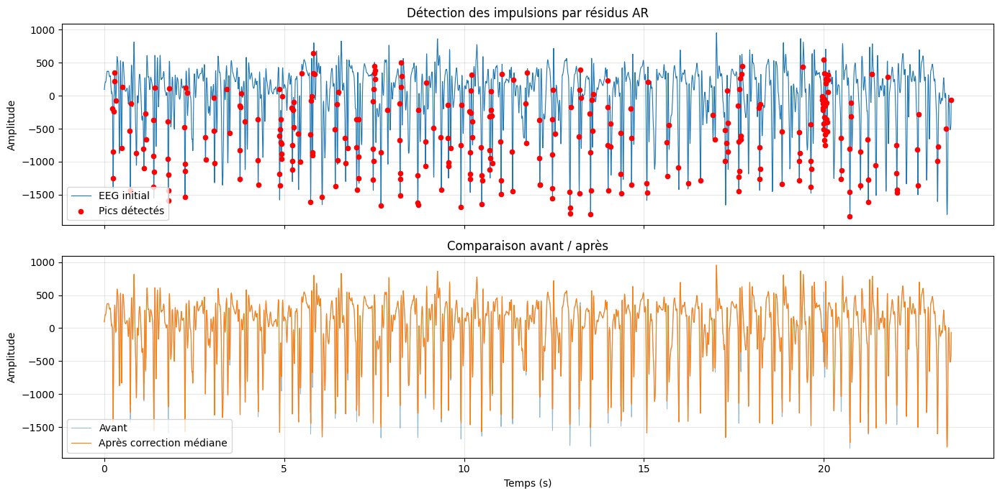

Points détectés : 299 / 4097
Pourcentage détecté : 7.298 %


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter


def denoiser_eeg_ar_median(
    signal,
    fs=174.0,
    ordre_ar=10,
    seuil=5.0,
    taille_mediane=5,
    iterations=5,
):
    """
    Détecte les impulsions avec un modèle AR et les corrige
    par remplacement médian local.

    Paramètres
    ----------
    signal : array_like
        Signal EEG unidimensionnel.
    fs : float
        Fréquence d'échantillonnage en Hz (informatif).
    ordre_ar : int
        Ordre du modèle autorégressif.
    seuil : float
        Seuil sur les résidus, en écarts-types robustes.
    taille_mediane : int
        Taille impaire de la fenêtre médiane de correction.
    iterations : int
        Nombre maximal de réajustements robustes du modèle.

    Returns
    -------
    signal_corrige : ndarray
        Signal où les impulsions détectées sont remplacées.
    masque : ndarray of bool
        True aux positions détectées comme impulsions.
    residus : ndarray
        Résidus du modèle AR final.
    """
    x = np.asarray(signal, dtype=float).squeeze()

    if x.ndim != 1:
        raise ValueError("Le signal doit être unidimensionnel.")
    if not np.all(np.isfinite(x)):
        raise ValueError("Le signal contient des NaN ou des infinis.")
    if not 1 <= ordre_ar < len(x) - 1:
        raise ValueError("Ordre AR incompatible avec la longueur du signal.")
    if taille_mediane < 3 or taille_mediane % 2 == 0:
        raise ValueError("taille_mediane doit être impaire et >= 3.")
    if seuil <= 0 or iterations < 1:
        raise ValueError("seuil et iterations doivent être positifs.")

    n = len(x)
    p = ordre_ar

    # Construction du modèle : x[t] = a1*x[t-1] + ... + ap*x[t-p]
    y = x[p:]
    X = np.column_stack([
        x[p - lag - 1:n - lag - 1]
        for lag in range(p)
    ])

    # Une ligne est exclue si sa cible ou l'un de ses prédicteurs
    # contient un échantillon déjà détecté comme aberrant.
    masque = np.zeros(n, dtype=bool)

    def ajuster_ar(masque_points):
        valide = np.ones(len(y), dtype=bool)

        # Exclure les cibles aberrantes
        valide &= ~masque_points[p:]

        # Exclure aussi les lignes dont les prédicteurs sont contaminés
        for lag in range(1, p + 1):
            valide &= ~masque_points[p - lag:n - lag]

        if valide.sum() <= p:
            raise ValueError(
                "Pas assez d'échantillons valides pour ajuster le modèle AR."
            )

        coefficients, *_ = np.linalg.lstsq(
            X[valide], y[valide], rcond=None
        )
        return coefficients

    def echelle_robuste(r):
        med = np.median(r)
        mad = np.median(np.abs(r - med))
        return med, 1.4826 * mad

    # Ajustement itératif : réduire l'influence des pics sur le modèle
    for _ in range(iterations):
        coefficients = ajuster_ar(masque)
        residus = y - X @ coefficients

        centre, sigma = echelle_robuste(residus)

        if sigma <= np.finfo(float).eps:
            break

        nouveaux = np.abs(residus - centre) > seuil * sigma

        masque_nouveau = masque.copy()
        masque_nouveau[p:] |= nouveaux

        if np.array_equal(masque_nouveau, masque):
            break

        masque = masque_nouveau

    # Réajustement final et détection avec les résidus finaux
    coefficients = ajuster_ar(masque)
    residus = y - X @ coefficients

    centre, sigma = echelle_robuste(residus)

    if sigma > np.finfo(float).eps:
        masque_final = np.abs(residus - centre) > seuil * sigma
        masque[p:] |= masque_final

    # Remplacer seulement les points détectés par la médiane locale
    mediane_locale = median_filter(
        x, size=taille_mediane, mode="nearest"
    )

    signal_corrige = x.copy()
    signal_corrige[masque] = mediane_locale[masque]

    return signal_corrige, masque, residus


# ============================================================
# EXEMPLE SUR UN SEGMENT EEG
# ============================================================

classe = "A"
indice = 0
fs = 174.0


from pathlib import Path
import numpy as np

DOSSIER = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/"
    "detrend_filtre50_filtre1_80"
)

data_detrend_filtre = {}

for classe_dir in sorted(DOSSIER.iterdir()):
    if not classe_dir.is_dir():
        continue

    fichiers = sorted(classe_dir.glob("*.npy"))

    data_detrend_filtre[classe_dir.name] = [
        np.load(fichier, allow_pickle=False)
        for fichier in fichiers
    ]

print("Classes chargées :", list(data_detrend_filtre.keys()))

for classe, segments in data_detrend_filtre.items():
    print(f"Classe {classe} : {len(segments)} segments")
    if segments:
        print("  Forme du premier segment :", segments[0].shape)


signal = np.asarray(data_detrend_filtre[classe][indice], dtype=float)

corrige, masque, residus = denoiser_eeg_ar_median(
    signal,
    fs=fs,
    ordre_ar=10,
    seuil=5.0,
    taille_mediane=5,
    iterations=5,
)

temps = np.arange(len(signal)) / fs

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(temps, signal, linewidth=0.8, label="EEG initial")
axes[0].scatter(
    temps[masque],
    signal[masque],
    color="red",
    s=20,
    label="Pics détectés",
    zorder=3,
)
axes[0].set_title("Détection des impulsions par résidus AR")
axes[0].set_ylabel("Amplitude")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(temps, signal, linewidth=0.7, alpha=0.5, label="Avant")
axes[1].plot(temps, corrige, linewidth=0.8, label="Après correction médiane")
axes[1].set_title("Comparaison avant / après")
axes[1].set_xlabel("Temps (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Points détectés : {masque.sum()} / {len(signal)}")
print(f"Pourcentage détecté : {100 * masque.mean():.3f} %")


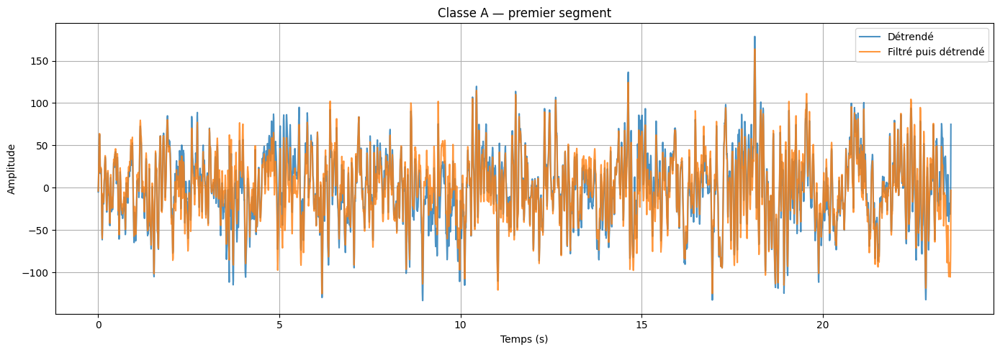

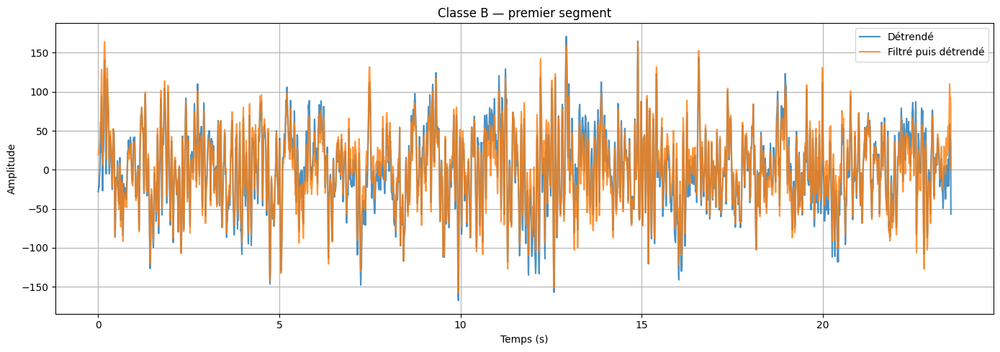

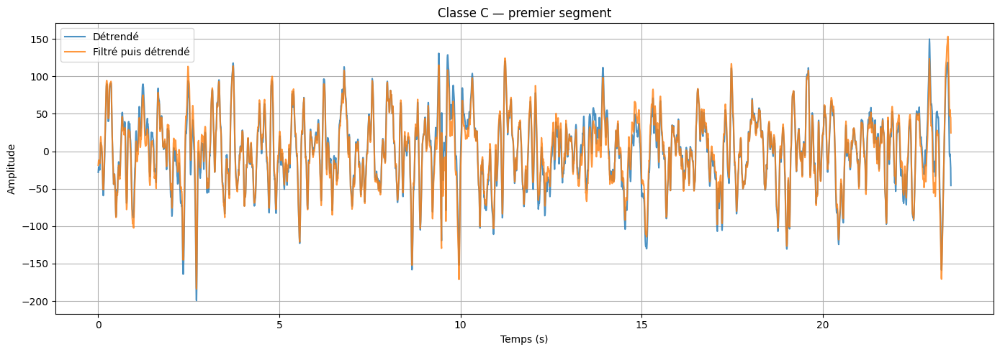

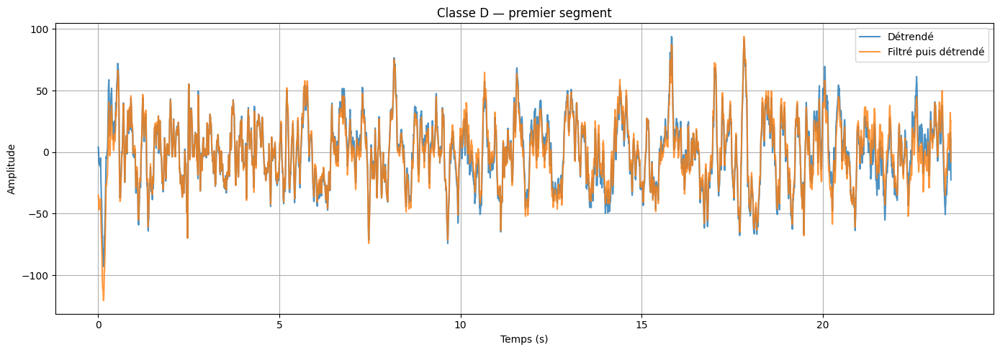

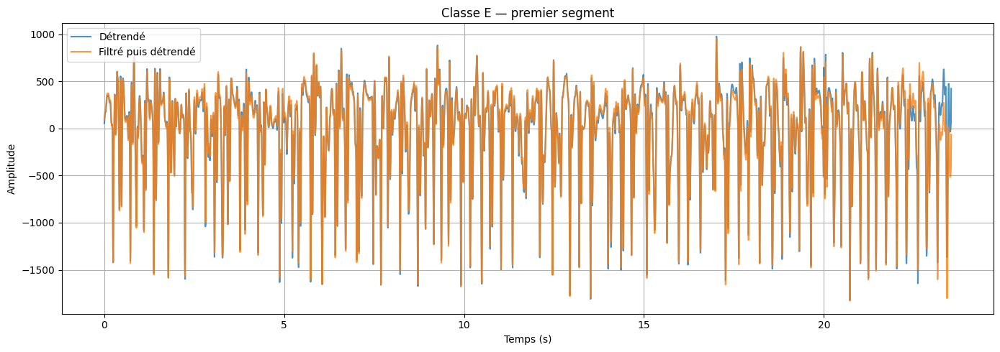

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DOSSIER_DETREND = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/sauvegardes_detrend_v2"
)

fs = 174  # Hz

for classe in sorted(data_detrend_filtre.keys()):
    # Premier segment de chaque dictionnaire
    signal_filtre_detrend = data_detrend_filtre[classe][0]

    # Charger le premier segment détrendé sans le filtrage préalable
    fichiers = sorted((DOSSIER_DETREND / classe).glob("*.npy"))
    if not fichiers:
        print(f"Aucun fichier trouvé pour la classe {classe}")
        continue

    signal_detrend = np.load(fichiers[0], allow_pickle=False)

    temps_filtre = np.arange(len(signal_filtre_detrend)) / fs
    temps_detrend = np.arange(len(signal_detrend)) / fs

    plt.figure(figsize=(14, 5))
    plt.plot(temps_detrend, signal_detrend, label="Détrendé", alpha=0.8)
    plt.plot(
        temps_filtre,
        signal_filtre_detrend,
        label="Filtré puis détrendé",
        alpha=0.8,
    )

    plt.title(f"Classe {classe} — premier segment")
    plt.xlabel("Temps (s)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [5]:
from pathlib import Path
import numpy as np
from pathlib import Path
import numpy as np

DOSSIER = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/"
    "detrend_filtre50_filtre1_80"
)

data_detrend_filtre = {}

for classe_dir in sorted(DOSSIER.iterdir()):
    if not classe_dir.is_dir():
        continue

    fichiers = sorted(classe_dir.glob("*.npy"))

    data_detrend_filtre[classe_dir.name] = [
        np.load(fichier, allow_pickle=False)
        for fichier in fichiers
    ]

print("Classes chargées :", list(data_detrend_filtre.keys()))

for classe, segments in data_detrend_filtre.items():
    print(f"Classe {classe} : {len(segments)} segments")
    if segments:
        print("  Forme du premier segment :", segments[0].shape)

# Dossier de sauvegarde
DOSSIER_SORTIE = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/detrend_filtre_denoise"
)

data_denoise = {}

for classe, segments in data_detrend_filtre.items():
    data_denoise[classe] = []

    dossier_classe = DOSSIER_SORTIE / classe
    dossier_classe.mkdir(parents=True, exist_ok=True)

    for i, signal in enumerate(segments):
        signal_corrige, masque, residus = denoiser_eeg_ar_median(
            signal,
            fs=174.0,
            ordre_ar=10,
            seuil=5.0,
            taille_mediane=5,
            iterations=5,
        )

        # En mémoire
        data_denoise[classe].append(signal_corrige)

        # Sur disque
        chemin = dossier_classe / f"segment_{i:04d}.npy"
        np.save(chemin, signal_corrige)

print("Dénoyage terminé.")
print("Dossier de sauvegarde :", DOSSIER_SORTIE)

for classe, segments in data_denoise.items():
    print(f"Classe {classe} : {len(segments)} segments")

Classes chargées : ['A', 'B', 'C', 'D', 'E']
Classe A : 100 segments
  Forme du premier segment : (4097,)
Classe B : 100 segments
  Forme du premier segment : (4097,)
Classe C : 100 segments
  Forme du premier segment : (4097,)
Classe D : 100 segments
  Forme du premier segment : (4097,)
Classe E : 100 segments
  Forme du premier segment : (4097,)
Dénoyage terminé.
Dossier de sauvegarde : /mnt/adisk/yassineferhi/traitement_signal/detrend_filtre_denoise
Classe A : 100 segments
Classe B : 100 segments
Classe C : 100 segments
Classe D : 100 segments
Classe E : 100 segments


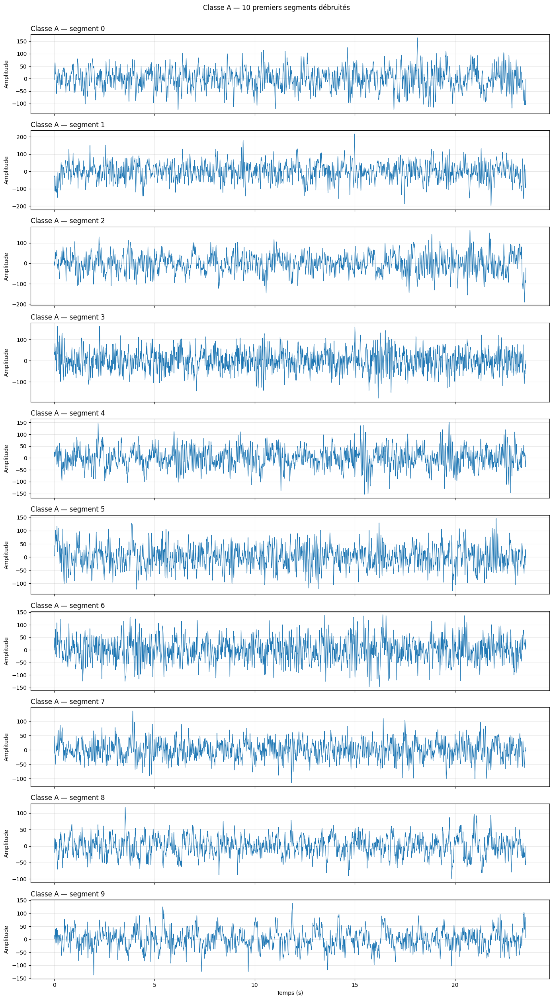

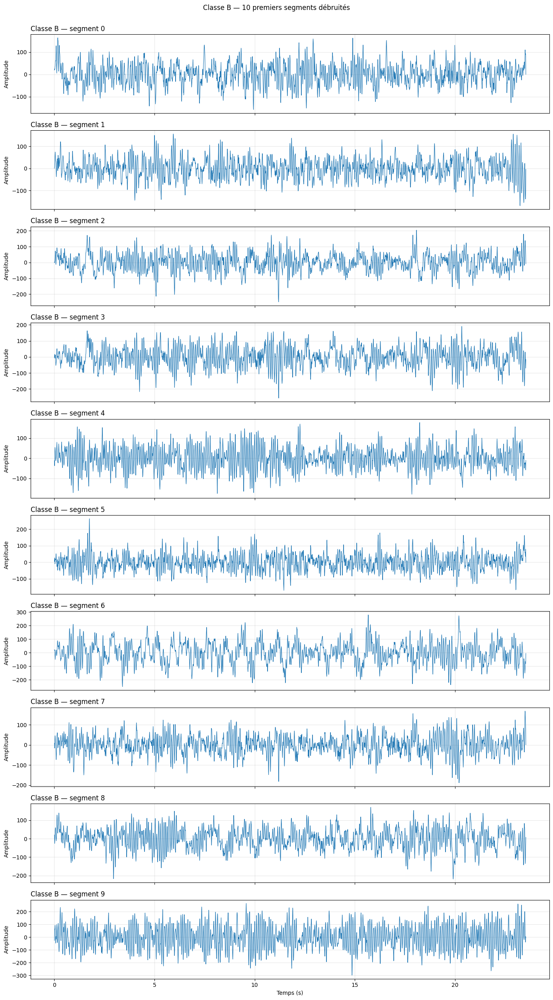

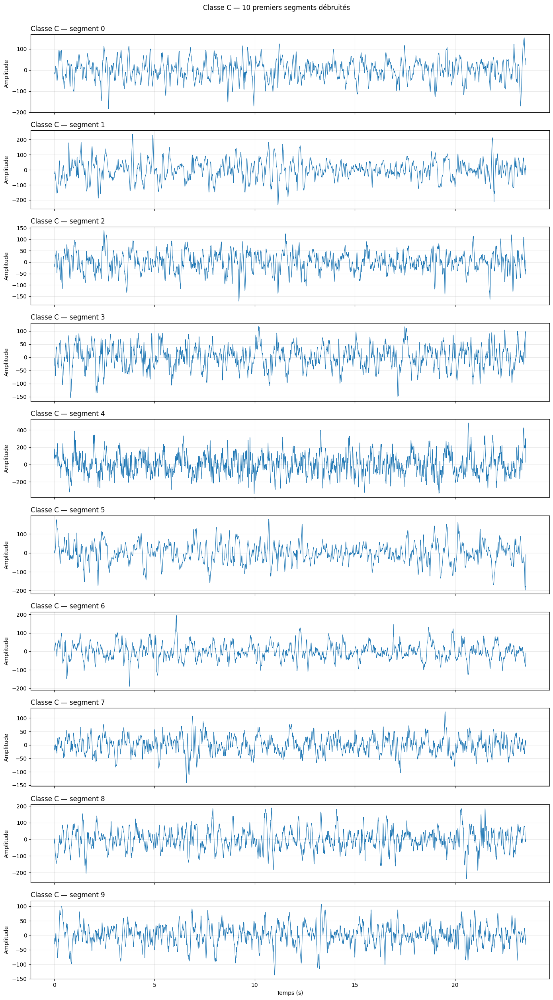

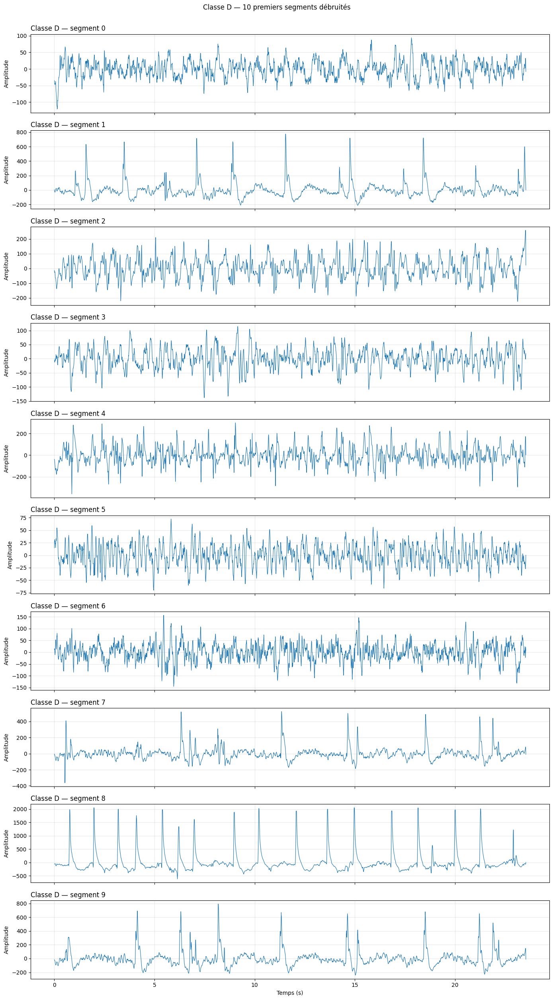

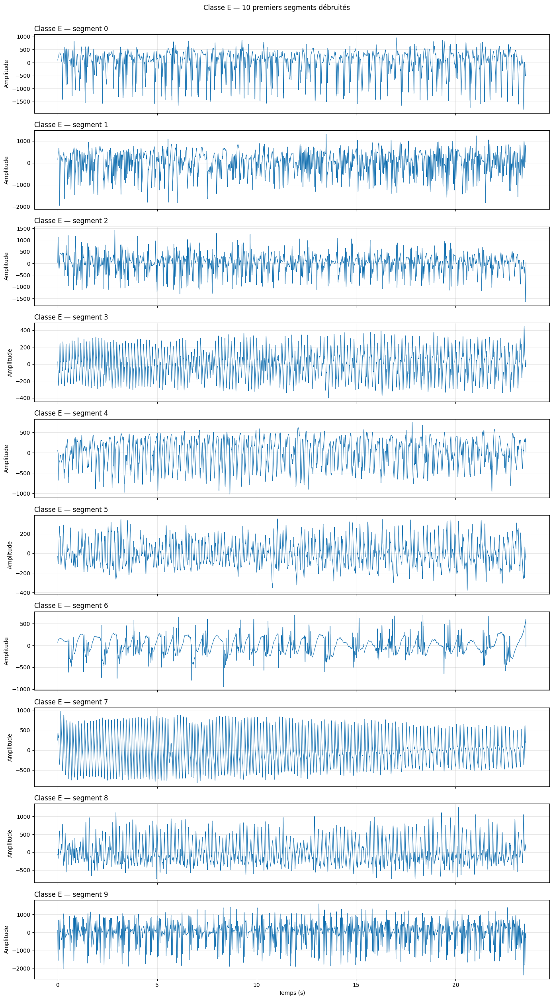

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fs = 174  # Fréquence d'échantillonnage en Hz
nombre_segments = 10

for classe in sorted(data_denoise.keys()):
    segments = data_denoise[classe][:nombre_segments]

    if not segments:
        continue

    fig, axes = plt.subplots(
        len(segments), 1,
        figsize=(14, 2.5 * len(segments)),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    for i, (ax, signal) in enumerate(zip(axes, segments)):
        signal = np.asarray(signal).squeeze()
        temps = np.arange(len(signal)) / fs

        ax.plot(temps, signal, linewidth=0.8)
        ax.set_title(f"Classe {classe} — segment {i}", loc="left")
        ax.set_ylabel("Amplitude")
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Temps (s)")
    fig.suptitle(
        f"Classe {classe} — {len(segments)} premiers segments débruités",
        y=1.002
    )
    fig.tight_layout()
    plt.show()

In [7]:

import numpy as np
from scipy.ndimage import median_filter


def denoiser_residus_ar_median(
    signal,
    ordre_ar=10,
    seuil=5.0,
    taille_mediane=5,
):
    """
    Détecte les impulsions en ajustant un modèle AR aux résidus
    d'un premier modèle AR, puis corrige les points détectés
    par une médiane locale.
    """
    x = np.asarray(signal, dtype=float).squeeze()

    if x.ndim != 1:
        raise ValueError("Le signal doit être unidimensionnel.")

    n = len(x)
    p = ordre_ar

    if not 1 <= p < n // 2:
        raise ValueError("Ordre AR invalide.")
    if taille_mediane < 3 or taille_mediane % 2 == 0:
        raise ValueError("La taille médiane doit être impaire et >= 3.")

    def ajuster_ar(y, p):
        cible = y[p:]
        matrice = np.column_stack([
            y[p - lag - 1:n - lag - 1]
            for lag in range(p)
        ])
        coefficients, *_ = np.linalg.lstsq(
            matrice, cible, rcond=None
        )
        prediction = matrice @ coefficients
        residus = cible - prediction
        return residus

    # Première régression AR sur le signal
    residus_1 = ajuster_ar(x, p)

    # Deuxième régression AR sur les résidus déjà obtenus
    residus_2 = ajuster_ar(residus_1, p)

    # Détection robuste sur les résidus de la seconde régression
    centre = np.median(residus_2)
    mad = np.median(np.abs(residus_2 - centre))
    sigma = 1.4826 * mad

    masque = np.zeros(n, dtype=bool)

    if sigma > np.finfo(float).eps:
        debut = 2 * p
        masque[debut:] = (
            np.abs(residus_2 - centre) > seuil * sigma
        )

    # Correction des points détectés dans le signal original
    signal_corrige = x.copy()
    mediane_locale = median_filter(
        x, size=taille_mediane, mode="nearest"
    )
    signal_corrige[masque] = mediane_locale[masque]

    return signal_corrige, masque, residus_2


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter


def denoiser_residus_ar_median(
    residus,
    ordre_ar=10,
    seuil=5.0,
    taille_mediane=5,
):
    """Détecte les impulsions dans les résidus via une régression AR."""
    x = np.asarray(residus, dtype=float).squeeze()

    if x.ndim != 1:
        raise ValueError("Les résidus doivent être un signal 1D.")

    n = len(x)
    p = ordre_ar
    if not 1 <= p < n:
        raise ValueError("Ordre AR invalide.")

    cible = x[p:]
    matrice = np.column_stack([
        x[p - lag - 1:n - lag - 1]
        for lag in range(p)
    ])

    coefficients, *_ = np.linalg.lstsq(matrice, cible, rcond=None)
    residus_prediction = cible - matrice @ coefficients

    centre = np.median(residus_prediction)
    mad = np.median(np.abs(residus_prediction - centre))
    sigma = 1.4826 * mad

    masque = np.zeros(n, dtype=bool)
    if sigma > np.finfo(float).eps:
        masque[p:] = (
            np.abs(residus_prediction - centre) > seuil * sigma
        )

    corrige = x.copy()
    med = median_filter(x, size=taille_mediane, mode="nearest")
    corrige[masque] = med[masque]

    return corrige, masque, residus_prediction


# Ici, remplace residus_deja_calcules par ton dictionnaire de résidus :
# residus_deja_calcules[classe] = liste des résidus de chaque segment.

data_residus_corriges = {}
masques_residus = {}

for classe, segments in residus_deja_calcules.items():
    data_residus_corriges[classe] = []
    masques_residus[classe] = []

    for residus in segments:
        corrige, masque, _ = denoiser_residus_ar_median(
            residus,
            ordre_ar=10,
            seuil=5.0,
            taille_mediane=5,
        )
        data_residus_corriges[classe].append(corrige)
        masques_residus[classe].append(masque)


# Tracer les dix premiers résidus corrigés de chaque classe
fs = 174

for classe in sorted(data_residus_corriges):
    segments = data_residus_corriges[classe][:10]
    if not segments:
        continue

    fig, axes = plt.subplots(
        len(segments), 1,
        figsize=(14, 2.2 * len(segments)),
        sharex=True,
    )
    axes = np.atleast_1d(axes)

    for i, (ax, signal) in enumerate(zip(axes, segments)):
        t = np.arange(len(signal)) / fs
        ax.plot(t, signal, linewidth=0.8)
        ax.set_title(f"Classe {classe} — résidu corrigé {i}", loc="left")
        ax.set_ylabel("Amplitude")
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Temps (s)")
    fig.tight_layout()
    plt.show()

NameError: name 'residus_deja_calcules' is not defined

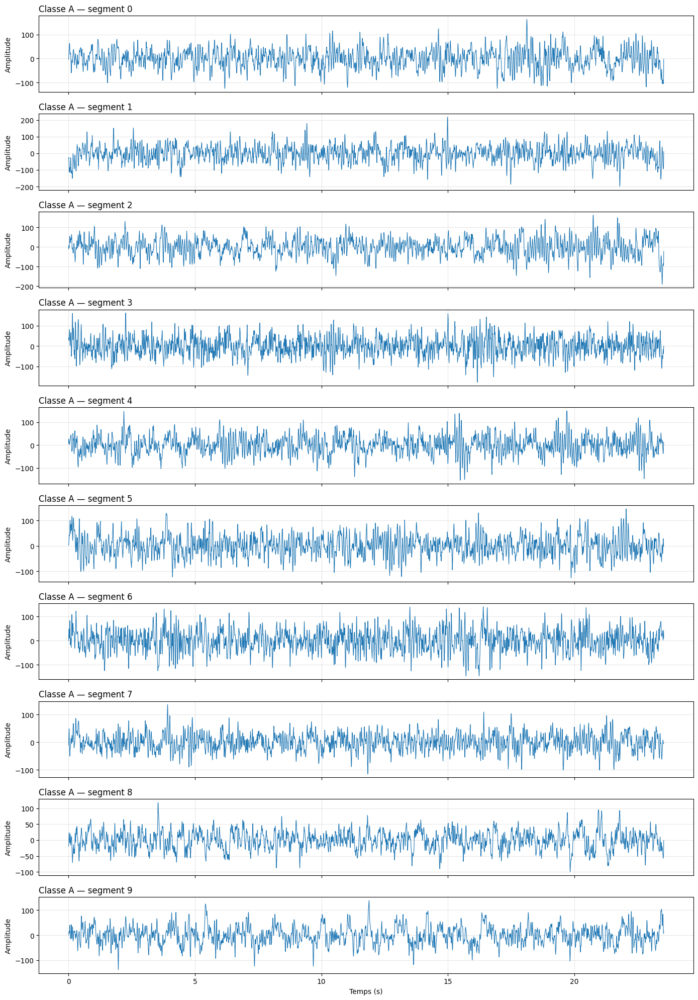

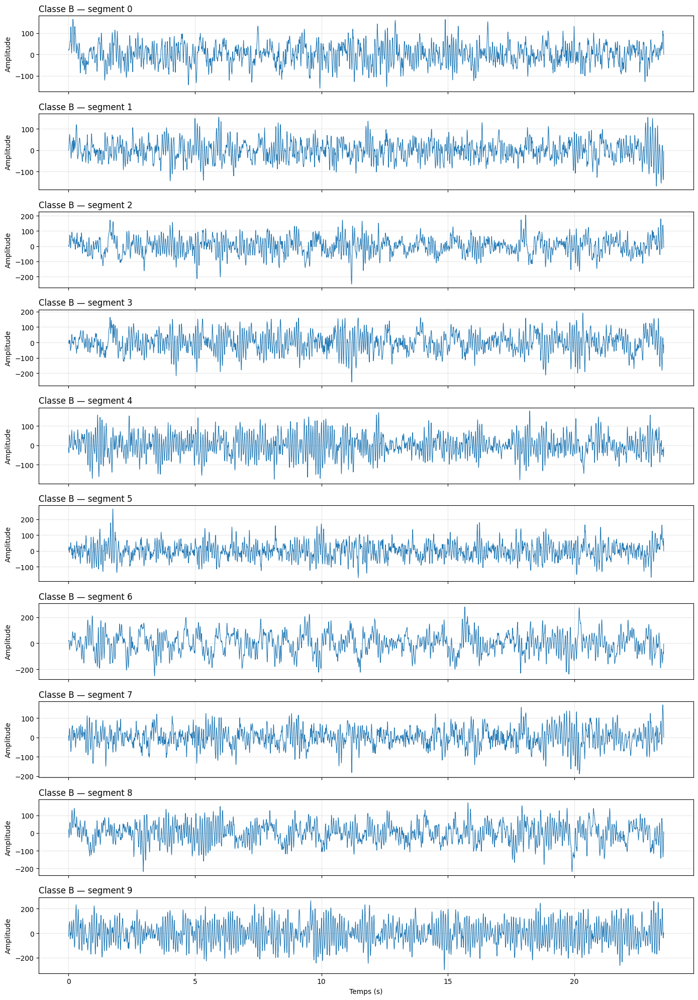

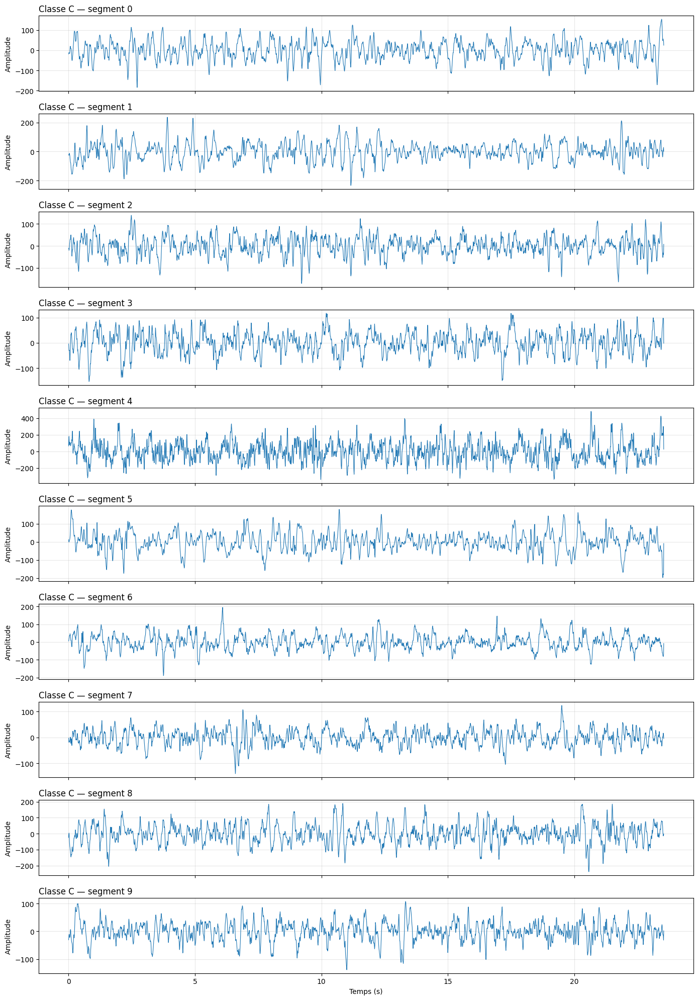

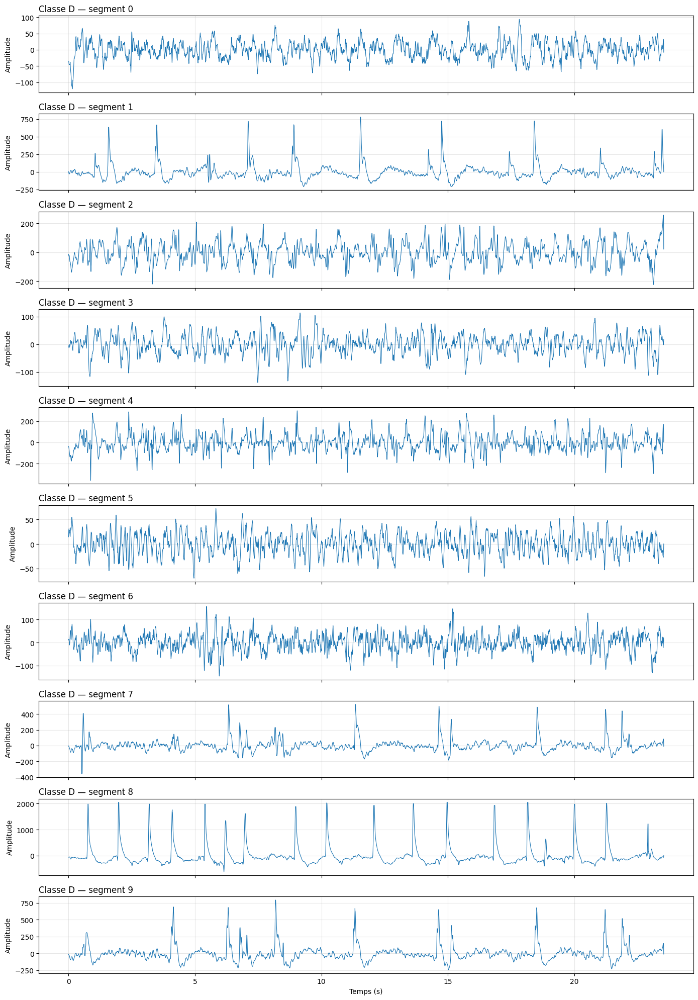

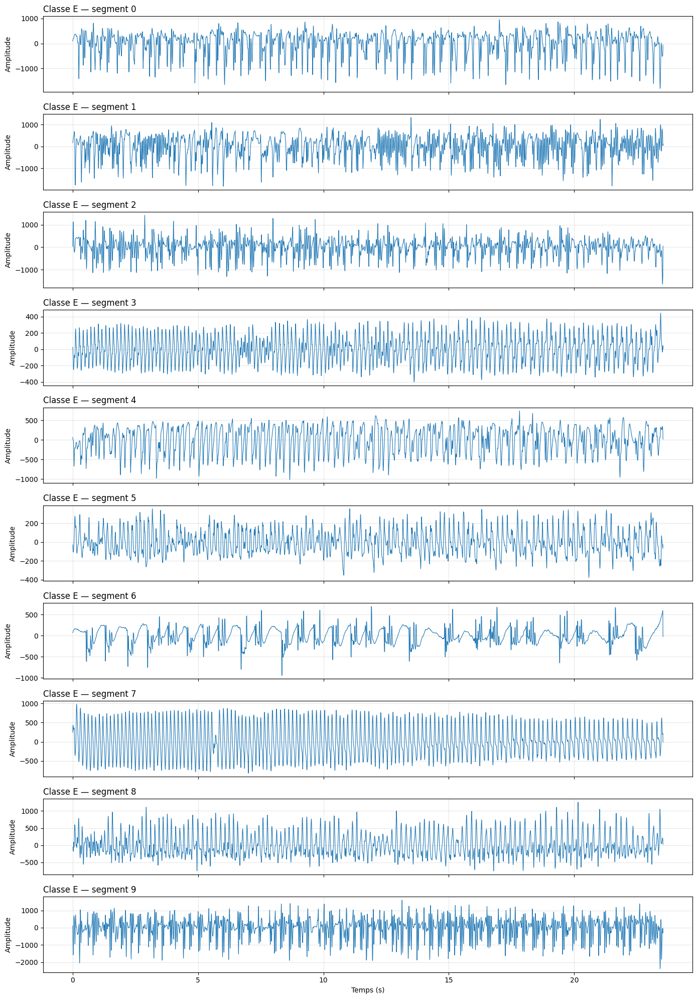

In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

# Charger les signaux du dossier existant
DOSSIER = Path(
    "/mnt/adisk/yassineferhi/traitement_signal/detrend_filtre_denoise"
)

data_residus = {}

for classe_dir in sorted(DOSSIER.iterdir()):
    if not classe_dir.is_dir():
        continue

    fichiers = sorted(classe_dir.glob("*.npy"))
    data_residus[classe_dir.name] = [
        np.load(f, allow_pickle=False) for f in fichiers
    ]

# Appliquer une régression AR aux signaux chargés
data_residus_corriges = {}
masques_residus = {}

for classe, segments in data_residus.items():
    data_residus_corriges[classe] = []
    masques_residus[classe] = []

    for x in segments:
        x = np.asarray(x, dtype=float).squeeze()
        p = 10

        cible = x[p:]
        matrice = np.column_stack([
            x[p-lag-1:len(x)-lag-1]
            for lag in range(p)
        ])

        coefficients, *_ = np.linalg.lstsq(
            matrice, cible, rcond=None
        )
        residus_prediction = cible - matrice @ coefficients

        centre = np.median(residus_prediction)
        mad = np.median(np.abs(residus_prediction - centre))
        sigma = 1.4826 * mad

        masque = np.zeros(len(x), dtype=bool)
        if sigma > np.finfo(float).eps:
            masque[p:] = (
                np.abs(residus_prediction - centre) > 5.0 * sigma
            )

        corrige = x.copy()
        med = median_filter(x, size=5, mode="nearest")
        corrige[masque] = med[masque]

        data_residus_corriges[classe].append(corrige)
        masques_residus[classe].append(masque)

# Tracer les dix premiers segments de chaque classe
fs = 174

for classe in sorted(data_residus_corriges):
    segments = data_residus_corriges[classe][:10]
    if not segments:
        continue

    fig, axes = plt.subplots(
        len(segments), 1,
        figsize=(14, 2 * len(segments)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for i, (ax, signal) in enumerate(zip(axes, segments)):
        temps = np.arange(len(signal)) / fs
        ax.plot(temps, signal, linewidth=0.8)
        ax.set_title(f"Classe {classe} — segment {i}", loc="left")
        ax.grid(True, alpha=0.3)
        ax.set_ylabel("Amplitude")

    axes[-1].set_xlabel("Temps (s)")
    fig.tight_layout()
    plt.show()